# PDAN8412 POE Part 3: Recognising Age Bands from Faces with a Convolutional Neural Network

Jordan Müller (ST10150702)

The book press wants to use facial recognition at its premises, and the first step the brief asks for is a CNN that can recognise images accurately. Instead of jumping straight to identifying individual people, I'm building the same pipeline (an aligned face goes in, a class comes out) on a task I can test properly with open data: predicting which age band a person falls in from a photo of their face, using the UTKFace dataset (Zhang, Song and Qi, 2017).

Spark does all the loading, quality checks, cleaning, EDA and the train/validation/test split, and the CNN is trained in TensorFlow/Keras, which the brief allows. Same approach as Part 2: every step has a Markdown cell explaining what I'm doing and why, the comments in the code sit above the lines they explain, and every EDA step ends with the modelling decision it leads to.

Setup: Python 3.11.9, PySpark 3.5.9, TensorFlow 2.21 and Java 17 in the same .venv as Parts 1 and 2. On top of Part 2's packages this part needs `pip install tensorflow pillow pyarrow` (Pillow decodes the images inside Spark and PyArrow moves batches between Spark and Python).

## 1. Setup and Data Loading

UTKFace ("Aligned & Cropped Faces" version) has 23,708 face photos, each 200 x 200 pixels, already cropped and aligned so the eyes sit in roughly the same place in every image. There's no separate label file. The labels are packed into each filename as `[age]_[gender]_[race]_[date&time].jpg.chip.jpg`, where gender is 0 (male) or 1 (female) and race is 0 to 4 (White, Black, Asian, Indian, Others), using the dataset's own category names.

The images go in `data/UTKFace/` next to this notebook.

In [1]:
# ---------------------------------------------------------------
# 1.1 Imports, Spark session and settings
# ---------------------------------------------------------------
import os
import sys
import io
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from PIL import Image
from scipy import stats

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window

# Spark launches separate Python worker processes. Pointing both the driver
# and the workers at this kernel's interpreter avoids the "Python worker
# failed to connect" error from Part 1.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .appName("PDAN8412_Part3_CNN_AgeBands")
    # use every local core
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    # Each image is a tiny file. By default Spark charges every file as if it were 4 MB,
    # which would give one task per handful of images. Charging 64 KB packs a few hundred per task.
    .config("spark.sql.files.openCostInBytes", str(64 * 1024))
    .config("spark.sql.files.maxPartitionBytes", str(32 * 1024 * 1024))
    .config("spark.sql.shuffle.partitions", "16")
    # Spark is given an explicit list of image files (see 1.2), and by default it checks each one
    # in its own task. This caps that check at 16 tasks instead of one per image.
    .config("spark.sql.sources.parallelPartitionDiscovery.parallelism", "16")
    # Arrow moves batches of rows between Spark and Python. Small batches keep the image bytes
    # held in memory at any one time under control.
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.execution.arrow.maxRecordsPerBatch", "500")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| Python", sys.version.split()[0])

SEED = 42
np.random.seed(SEED)

# Forward slashes work for both Spark and TensorFlow on Windows
IMG_DIR = "data/UTKFace"
for folder in ["figures", "models", "outputs"]:
    os.makedirs(folder, exist_ok=True)

# The brief asks for at least 10 000 records
MIN_RECORDS = 10_000

# Target: five life-stage age bands (explained in 1.4)
BAND_EDGES = [0, 13, 20, 35, 55, 200]
BAND_NAMES = ["0-12", "13-19", "20-34", "35-54", "55+"]
N_CLASSES = len(BAND_NAMES)
GENDER_NAMES = {0: "Male", 1: "Female"}
RACE_NAMES = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}

# Colours. The age bands are ordered, so they share one blue ramp from light (young) to dark (old).
# Unordered groups (gender, ethnicity, train vs validation) get clearly different colours instead.
BAND_COLOURS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
CAT_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#86b6ef", "#2a78d6", "#104281"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

# Keras warns that shuffle is ignored for tf.data inputs (the pipeline shuffles itself), and
# sklearn warns when a tiny group has no examples of a band. Neither affects the results.
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

def save_fig(name):
    """Save the current figure to figures/<name>.png at report resolution."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

Spark 3.5.9 | Python 3.11.9


In [2]:
# ---------------------------------------------------------------
# 1.2 Load every image file into Spark as raw bytes
# ---------------------------------------------------------------
# binaryFile gives one row per file with its path, size and raw bytes. Everything
# later (decoding, hashing, measuring) starts from exactly what is on disk.
#
# On Windows, Spark can't list the contents of a folder without Hadoop's native Windows library
# (hadoop.dll), which fails with "UnsatisfiedLinkError: NativeIO$Windows.access0". So Python lists
# the image files and Spark gets the exact paths, which it can read without listing anything.
IMG_FILES = [f"{IMG_DIR}/{f}" for f in sorted(os.listdir(IMG_DIR)) if f.endswith(".jpg")]
print(f"jpg files listed by Python: {len(IMG_FILES):,}")

raw = (
    spark.read.format("binaryFile")
    .load(IMG_FILES)
    # the filename (the last part of the path) is where the labels live
    .withColumn("filename", F.element_at(F.split("path", "/"), -1))
    .select("filename", "length", "content")
)
# cached because the hashing, decoding and label parsing all start from this frame
raw.cache()

n_files = raw.count()
sizes = raw.agg(
    F.sum("length").alias("total"), F.min("length").alias("min_b"),
    F.expr("percentile_approx(length, 0.5)").alias("median_b"), F.max("length").alias("max_b"),
).first()
print(f"image files found: {n_files:,}")
print(f"total size on disk: {sizes['total'] / 1e6:.1f} MB")
print(f"file size: min {sizes['min_b']:,} B | median {sizes['median_b']:,} B | max {sizes['max_b']:,} B")

jpg files listed by Python: 23,708
image files found: 23,708
total size on disk: 120.0 MB
file size: min 2,060 B | median 4,972 B | max 12,025 B


**Findings:** written from the real outputs after the full run.

### 1.3 Structural check with Spark's built-in image reader

Spark has its own image data source that decodes each file and reports its height, width and number of colour channels. I'm using it as an independent first check: with `dropInvalid` turned off, any file Spark can't decode still comes back as a row, just with -1 in every field, so broken files get counted instead of silently disappearing.

In [3]:
# ---------------------------------------------------------------
# 1.3 Height, width, channels and unreadable files (Spark image source)
# ---------------------------------------------------------------
img_meta = (
    spark.read.format("image")
    .option("dropInvalid", False)
    .load(IMG_FILES)
    .select(
        F.element_at(F.split("image.origin", "/"), -1).alias("filename"),
        F.col("image.height").alias("height"),
        F.col("image.width").alias("width"),
        F.col("image.nChannels").alias("channels"),
    )
)
img_meta.cache()

print(f"rows from the image reader: {img_meta.count():,}")
print(f"files Spark could not decode: {img_meta.filter('channels < 0').count()}")
print("\nimage shapes (height x width x channels):")
img_meta.groupBy("height", "width", "channels").count().orderBy(F.desc("count")).show(10)

rows from the image reader: 23,708
files Spark could not decode: 0

image shapes (height x width x channels):
+------+-----+--------+-----+
|height|width|channels|count|
+------+-----+--------+-----+
|   200|  200|       3|23708|
+------+-----+--------+-----+



**Findings:** written from the real outputs after the full run.

### 1.4 Parsing the labels and defining the target

The labels are pulled out of each filename with a regular expression. Anything that doesn't match the `age_gender_race_datetime` pattern, or has a value outside the documented ranges (age 0-116, gender 0-1, race 0-4), is flagged instead of being quietly cast into a wrong number.

**Why age bands and not exact age?** The photos were collected from the web, so the ages can only be estimates (I test how rough they are in 3.1). Predicting an exact age would mean treating those estimates as precise, while grouping them into bands only needs the label to be roughly right. The five bands follow life stages: children (0-12), teenagers (13-19), young adults (20-34), adults (35-54) and older adults (55+). Teenagers get their own band on purpose, because for a premises system knowing whether someone is a minor matters most (POPIA treats children's personal information as a special category). The bands are ordered, so later I also measure how far off a wrong prediction is, not just whether it's wrong.

In [4]:
# ---------------------------------------------------------------
# 1.4 Labels from filenames, validity checks and the age band target
# ---------------------------------------------------------------
LABEL_PATTERN = r"^(\d+)_(\d+)_(\d+)_(\d+)"

def label_part(i):
    """Return field i of the filename pattern as an int. regexp_extract gives "" when the
    pattern doesn't match, so that is turned into null instead of being cast to a number."""
    value = F.regexp_extract("filename", LABEL_PATTERN, i)
    return F.when(value != "", value.cast("int"))

# Band index from age: count how many band edges (after 0) the age has reached
band_idx_expr = sum((F.col("age") >= edge).cast("int") for edge in BAND_EDGES[1:-1])

labels = (
    raw.select("filename")
    .withColumn("age", label_part(1))
    .withColumn("gender", label_part(2))
    .withColumn("race", label_part(3))
    .withColumn("label_ok", F.coalesce(
        F.col("age").between(0, 116) & F.col("gender").isin(0, 1) & F.col("race").isin(0, 1, 2, 3, 4),
        F.lit(False)))
    .withColumn("band_idx", F.when(F.col("label_ok"), band_idx_expr))
    .withColumn("band", F.element_at(F.array(*[F.lit(b) for b in BAND_NAMES]), F.col("band_idx") + 1))
)
labels.cache()

n_bad_pattern = labels.filter(F.col("age").isNull()).count()
n_bad_value = labels.filter(F.col("age").isNotNull() & ~F.col("label_ok")).count()
print(f"filenames that don't match the pattern: {n_bad_pattern}")
print(f"filenames with an out-of-range value: {n_bad_value}")
labels.filter(~F.col("label_ok")).select("filename", "age", "gender", "race").show(truncate=False)

print("age range:", labels.agg(F.min("age"), F.max("age")).first())
labels.groupBy("gender").count().orderBy("gender").show()
labels.groupBy("race").count().orderBy("race").show()

filenames that don't match the pattern: 3
filenames with an out-of-range value: 0
+-----------------------------------+----+------+----+
|filename                           |age |gender|race|
+-----------------------------------+----+------+----+
|61_1_20170109150557335.jpg.chip.jpg|NULL|NULL  |NULL|
|61_1_20170109142408075.jpg.chip.jpg|NULL|NULL  |NULL|
|39_1_20170116174525125.jpg.chip.jpg|NULL|NULL  |NULL|
+-----------------------------------+----+------+----+

age range: Row(min(age)=1, max(age)=116)
+------+-----+
|gender|count|
+------+-----+
|  NULL|    3|
|     0|12391|
|     1|11314|
+------+-----+

+----+-----+
|race|count|
+----+-----+
|NULL|    3|
|   0|10078|
|   1| 4526|
|   2| 3434|
|   3| 3975|
|   4| 1692|
+----+-----+



**Findings:** written from the real outputs after the full run.

## 2. Data Quality and Cleaning

Image data has quality problems that a missing-value count would never find: files that won't decode, black-and-white photos mixed in with colour ones, blurry or badly lit photos, and the same photo saved more than once. Duplicates are the dangerous one. If a copy of a photo lands in training and another copy lands in testing, the model gets tested on an image it has already memorised, and the test score is inflated.

### 2.1 Measuring every image inside Spark

`mapInPandas` sends batches of raw image bytes to Python workers, where Pillow decodes each image and measures:

| Measure | How | Why |
|---|---|---|
| width, height, mode | from the decoded image | confirms the shape check in 1.3 |
| brightness | mean luminance (0-255) | lighting differences between bands could become a shortcut |
| contrast | standard deviation of luminance | flat, washed-out photos |
| sharpness | variance of the Laplacian (Pech-Pacheco et al., 2000) | blur hides wrinkles and skin texture, which is the age signal |
| saturation | mean HSV saturation (0-255) | colour vs faded or old photos |
| grayscale flag | the three colour channels are (almost) identical | black-and-white photos stored as colour files |
| dHash | 64-bit difference hash of a 9 x 8 thumbnail (Krawetz, 2013) | finds near-duplicate photos in 2.3 |
| thumbnail | 32 x 32 grayscale pixels | builds the average face per band in 3.5 |

An exact SHA-256 hash of the file bytes is computed with Spark's own `sha2` function to catch exact duplicate files.

In [5]:
# ---------------------------------------------------------------
# 2.1 Decode and measure every image on Spark's Python workers
# ---------------------------------------------------------------
THUMB = 32
# Mean absolute difference between colour channels (0-255 scale) below which a photo
# counts as black and white. JPEG compression leaves small colour noise even in
# grayscale photos, so the cut-off can't be exactly 0.
GRAY_THRESHOLD = 2.0
LUMA = np.array([0.299, 0.587, 0.114], dtype=np.float32)

STATS_SCHEMA = T.StructType([
    T.StructField("filename", T.StringType()),
    T.StructField("decoded", T.BooleanType()),
    T.StructField("width", T.IntegerType()),
    T.StructField("height", T.IntegerType()),
    T.StructField("mode", T.StringType()),
    T.StructField("brightness", T.DoubleType()),
    T.StructField("contrast", T.DoubleType()),
    T.StructField("sharpness", T.DoubleType()),
    T.StructField("saturation", T.DoubleType()),
    T.StructField("channel_diff", T.DoubleType()),
    T.StructField("dhash", T.LongType()),
    T.StructField("thumb", T.ArrayType(T.FloatType())),
])

def describe_image(filename, data):
    """Decode one JPEG and return its quality measures. Files that can't be decoded come
    back with decoded=False instead of crashing the whole Spark job."""
    failed = {"filename": filename, "decoded": False, "width": -1, "height": -1, "mode": None,
              "brightness": float("nan"), "contrast": float("nan"), "sharpness": float("nan"),
              "saturation": float("nan"), "channel_diff": float("nan"), "dhash": 0,
              "thumb": [0.0] * (THUMB * THUMB)}
    try:
        img = Image.open(io.BytesIO(data))
        img.load()
        rgb_img = img.convert("RGB")
    except Exception:
        return failed

    rgb = np.asarray(rgb_img, dtype=np.float32)
    lum = rgb @ LUMA
    # Laplacian = 4 x centre pixel minus its four neighbours. Its variance is high when
    # there are lots of sharp edges and low when the photo is blurry.
    lap = (4 * lum[1:-1, 1:-1] - lum[:-2, 1:-1] - lum[2:, 1:-1] - lum[1:-1, :-2] - lum[1:-1, 2:])
    sat = np.asarray(rgb_img.convert("HSV"), dtype=np.float32)[..., 1]
    chan_diff = (np.abs(rgb[..., 0] - rgb[..., 1]).mean() + np.abs(rgb[..., 1] - rgb[..., 2]).mean()) / 2

    # dHash: shrink to 9 x 8 grayscale and record whether each pixel is brighter than its right-hand
    # neighbour. Re-saving, resizing or slightly brightening a photo barely changes these 64 bits.
    small = np.asarray(rgb_img.convert("L").resize((9, 8), Image.LANCZOS), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    h = int("".join("1" if b else "0" for b in bits), 2)
    # Spark's LongType is signed, so the unsigned 64-bit hash is stored as its signed equivalent
    if h >= 2 ** 63:
        h -= 2 ** 64

    thumb = np.asarray(rgb_img.convert("L").resize((THUMB, THUMB), Image.BILINEAR), dtype=np.float32) / 255.0
    return {"filename": filename, "decoded": True, "width": img.width, "height": img.height, "mode": img.mode,
            "brightness": float(lum.mean()), "contrast": float(lum.std()), "sharpness": float(lap.var()),
            "saturation": float(sat.mean()), "channel_diff": float(chan_diff), "dhash": h,
            "thumb": thumb.flatten().tolist()}

def image_stats(batches):
    """mapInPandas entry point: Spark hands over an iterator of pandas batches of raw bytes."""
    for pdf in batches:
        yield pd.DataFrame([describe_image(f, b) for f, b in zip(pdf["filename"], pdf["content"])])

stats_df = raw.select("filename", "content").mapInPandas(image_stats, schema=STATS_SCHEMA)

images = (
    raw.select("filename", F.sha2("content", 256).alias("sha"))
    .join(stats_df, "filename")
    .join(labels, "filename")
    .withColumn("is_gray", F.col("decoded") & (F.col("channel_diff") < GRAY_THRESHOLD))
)
images.cache()

print(f"images measured: {images.count():,}")
print(f"failed to decode: {images.filter(~F.col('decoded')).count()}")
images.filter("decoded").groupBy("mode", "width", "height").count().orderBy(F.desc("count")).show(5)
print(f"black-and-white photos: {images.filter('is_gray').count():,}")
(images.filter("decoded")
 .select("brightness", "contrast", "sharpness", "saturation", "channel_diff")
 .summary("min", "25%", "50%", "75%", "max").show())

images measured: 23,708
failed to decode: 0
+----+-----+------+-----+
|mode|width|height|count|
+----+-----+------+-----+
| RGB|  200|   200|23708|
+----+-----+------+-----+

black-and-white photos: 697
+-------+------------------+-----------------+------------------+------------------+------------------+
|summary|        brightness|         contrast|         sharpness|        saturation|      channel_diff|
+-------+------------------+-----------------+------------------+------------------+------------------+
|    min| 25.81700897216797|12.64700698852539| 1.330115795135498|               0.0|               0.0|
|    25%|105.30752563476562|41.18266296386719|17.865468978881836| 79.42279815673828|22.033037185668945|
|    50%|   124.47607421875|49.43647384643555| 31.83829116821289| 99.35167694091797| 28.01089859008789|
|    75%|144.37574768066406|58.57258605957031|60.406375885009766| 119.9312973022461| 34.28398895263672|
|    max| 239.3958282470703|104.8879165649414|  4627.45361328125|239.

**Findings:** written from the real outputs after the full run.

### 2.2 Exact duplicates

Two files with the same SHA-256 hash are byte-for-byte the same photo. For every duplicate group I also check whether the copies carry the same labels. If they don't, the same face has been given two different ages (or genders), which is direct evidence of label noise. Since there's no way to know which label is right, those groups get dropped completely. Groups whose copies agree keep one copy.

In [6]:
# ---------------------------------------------------------------
# 2.2 Exact duplicate files and whether their labels agree
# ---------------------------------------------------------------
dup_groups = (
    images.filter("decoded")
    .groupBy("sha")
    .agg(F.count("*").alias("copies"),
         F.countDistinct("age", "gender", "race").alias("label_versions"),
         F.collect_list("filename").alias("files"))
    .filter("copies > 1")
)
dup_groups.cache()
dup_summary = dup_groups.agg(
    F.count("*").alias("groups"), F.sum(F.col("copies") - 1).alias("extra_copies"),
    F.sum((F.col("label_versions") > 1).cast("int")).alias("groups_with_conflicting_labels"),
).first()
print(dup_summary)
dup_groups.orderBy(F.desc("label_versions"), F.desc("copies")).select("copies", "label_versions", "files").show(8, truncate=110)

# Keep decodable images with valid labels, drop every copy of a conflicting group,
# and keep only the first copy (alphabetically) of an agreeing group
valid = images.filter("decoded AND label_ok")
conflicting = (valid.groupBy("sha").agg(F.countDistinct("age", "gender", "race").alias("v"))
               .filter("v > 1").select("sha"))
deduped = (
    valid.join(conflicting, "sha", "left_anti")
    .withColumn("copy_rank", F.row_number().over(Window.partitionBy("sha").orderBy("filename")))
    .filter("copy_rank = 1")
    .drop("copy_rank")
)
deduped.cache()
print(f"images after removing exact duplicates: {deduped.count():,}")

Row(groups=375, extra_copies=390, groups_with_conflicting_labels=259)
+------+--------------+--------------------------------------------------------------------------------------------------------------+
|copies|label_versions|                                                                                                         files|
+------+--------------+--------------------------------------------------------------------------------------------------------------+
|     3|             3|[51_0_1_20170117190816460.jpg.chip.jpg, 54_0_1_20170117173717615.jpg.chip.jpg, 56_0_1_20170120222838627.jpg...|
|     3|             3|[71_1_0_20170110141059193.jpg.chip.jpg, 72_1_0_20170110125258812.jpg.chip.jpg, 75_1_0_20170110182959300.jpg...|
|     3|             3|[25_1_3_20170119172045713.jpg.chip.jpg, 25_1_0_20170119172023545.jpg.chip.jpg, 32_1_0_20170104234919354.jpg...|
|     3|             3|[53_0_0_20170111200627419.jpg.chip.jpg, 55_0_0_20170111202253255.jpg.chip.jpg, 56_0_0_20170111222

**Findings:** written from the real outputs after the full run.

### 2.3 Near duplicates

Exact hashes miss photos that were re-saved, resized or slightly edited, because one changed pixel changes the whole SHA-256 hash. The dHash from 2.1 is built for this: near-identical photos get hashes that differ in only a few of their 64 bits (the Hamming distance).

Comparing every pair of 20,000+ images would mean over 200 million comparisons, so I use a blocking trick in Spark. Each hash is cut into four 16-bit pieces. If two hashes differ in 3 bits or fewer, at least one of the four pieces has to be identical (3 differences can't touch all 4 pieces), so I only compare images that share a piece. That catches every pair within 3 bits while comparing a tiny fraction of all pairs.

A matching hash on its own isn't proof, though. All the faces are aligned, so two different people can end up with very similar 64-bit gradient patterns by chance, and one chance match can chain whole clusters of strangers together. So every candidate pair also has to pass a second, stricter test: the correlation between the two 32 x 32 thumbnails from 2.1 must be at least 0.98. Spark computes that correlation itself with its array functions (`zip_with` and `aggregate`), and correlation ignores overall brightness and contrast, so a re-saved or slightly brightened copy still scores close to 1.

Near-duplicate pairs aren't deleted. Instead, each connected cluster of near duplicates gets a group ID, and Section 4 keeps a whole group in the same split. That way a false match costs nothing, but a real one can't leak across train and test.

In [7]:
# ---------------------------------------------------------------
# 2.3 Near-duplicate pairs by dHash, blocked self-join in Spark
# ---------------------------------------------------------------
HAMMING_MAX = 3
# A candidate pair only counts as a near duplicate if the thumbnails are almost identical too
THUMB_CORR_MIN = 0.98

# Four 16-bit pieces of each hash, one row per piece
pieces = F.array(*[F.shiftrightunsigned("dhash", 16 * k).bitwiseAND(0xFFFF) for k in range(4)])
blocked = deduped.select("filename", "dhash", "age", "thumb", F.posexplode(pieces).alias("piece_pos", "piece_val"))

a, b = blocked.alias("a"), blocked.alias("b")
near_pairs = (
    a.join(b, (F.col("a.piece_pos") == F.col("b.piece_pos"))
              & (F.col("a.piece_val") == F.col("b.piece_val"))
              # each pair once, never an image with itself
              & (F.col("a.filename") < F.col("b.filename")))
    .select(F.col("a.filename").alias("f1"), F.col("b.filename").alias("f2"),
            F.col("a.age").alias("age1"), F.col("b.age").alias("age2"),
            F.col("a.dhash").alias("h1"), F.col("b.dhash").alias("h2"),
            F.col("a.thumb").alias("t1"), F.col("b.thumb").alias("t2"))
    # a pair sharing two or more pieces would otherwise appear more than once
    .dropDuplicates(["f1", "f2"])
    # XOR leaves a 1 wherever the hashes differ, and bit_count counts them
    .withColumn("hamming", F.expr("bit_count(h1 ^ h2)"))
    .filter(F.col("hamming") <= HAMMING_MAX)
    # Pearson correlation of the two thumbnails, built from running sums over the 1,024 pixel pairs
    .withColumn("thumb_corr", F.expr(f"""
        aggregate(
            zip_with(t1, t2, (x, y) -> named_struct('xy', x * y, 'x', x, 'y', y, 'xx', x * x, 'yy', y * y)),
            named_struct('xy', 0D, 'x', 0D, 'y', 0D, 'xx', 0D, 'yy', 0D),
            (acc, s) -> named_struct('xy', acc.xy + s.xy, 'x', acc.x + s.x, 'y', acc.y + s.y,
                                     'xx', acc.xx + s.xx, 'yy', acc.yy + s.yy),
            acc -> (acc.xy - acc.x * acc.y / {THUMB * THUMB})
                   / sqrt((acc.xx - acc.x * acc.x / {THUMB * THUMB}) * (acc.yy - acc.y * acc.y / {THUMB * THUMB}) + 1e-12))
    """))
    .withColumn("age_gap", F.abs(F.col("age1") - F.col("age2")))
    .drop("t1", "t2")
)
candidates_pd = near_pairs.select("f1", "f2", "age1", "age2", "age_gap", "hamming", "thumb_corr").toPandas()
print(f"candidate pairs from the hash (Hamming <= {HAMMING_MAX}): {len(candidates_pd):,}")
print(candidates_pd["thumb_corr"].describe(percentiles=[0.5, 0.9, 0.99]).round(4).to_string())
pairs_pd = candidates_pd[candidates_pd["thumb_corr"] >= THUMB_CORR_MIN].reset_index(drop=True)
print(f"\nconfirmed near duplicates (thumbnail correlation >= {THUMB_CORR_MIN}): {len(pairs_pd):,}")
if len(pairs_pd):
    print(pairs_pd["hamming"].value_counts().sort_index().to_string())
    print(f"pairs whose ages disagree: {(pairs_pd.age_gap > 0).sum():,} | by more than 5 years: {(pairs_pd.age_gap > 5).sum():,}")

# Union-find: link every pair, so chains like A~B and B~C end up in one group {A, B, C}
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for f1, f2 in zip(pairs_pd["f1"], pairs_pd["f2"]):
    r1, r2 = find(f1), find(f2)
    if r1 != r2:
        parent[max(r1, r2)] = min(r1, r2)

group_rows = [(f, find(f)) for f in parent]
group_df = spark.createDataFrame(group_rows, schema="filename string, group_id string")
group_sizes = pd.Series([g for _, g in group_rows]).value_counts()
print(f"images in a near-duplicate group: {len(group_rows):,} | groups: {len(group_sizes):,} | "
      f"largest group: {group_sizes.max() if len(group_sizes) else 0} images")
# Real near duplicates come in twos and threes. A very large group means chance matches are
# chaining different people together, and the thresholds above should be tightened.
if len(group_sizes) and group_sizes.max() > 10:
    print(f"WARNING: a group of {group_sizes.max()} images looks like chained chance matches, "
          f"consider raising THUMB_CORR_MIN to 0.99")

candidate pairs from the hash (Hamming <= 3): 4,322
count    4322.0000
mean        0.8222
std         0.1061
min         0.2464
50%         0.8257
90%         0.9952
99%         0.9995
max         0.9999

confirmed near duplicates (thumbnail correlation >= 0.98): 577
hamming
0    221
1    193
2    117
3     46
pairs whose ages disagree: 441 | by more than 5 years: 148
images in a near-duplicate group: 1,049 | groups: 507 | largest group: 4 images


**Findings:** written from the real outputs after the full run.

### 2.4 Near-duplicate sanity check

Same idea as the matching check in Part 2: a hash match is only useful if it's really the same photo, so I look at a sample of pairs side by side. Aligned faces all have a similar overall structure, so this is where a false match would show up.

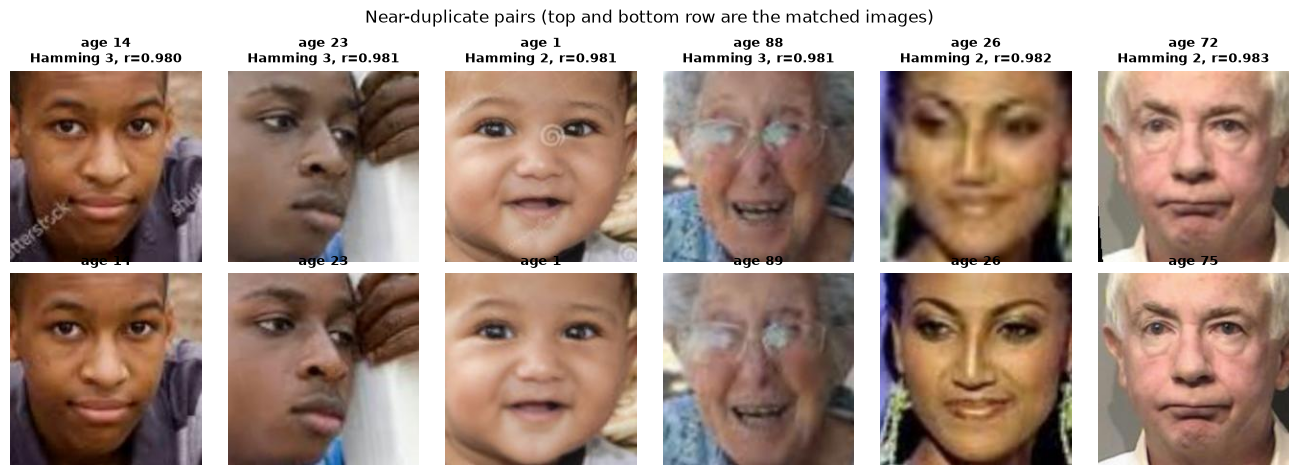

In [8]:
# ---------------------------------------------------------------
# 2.4 Eyeball a sample of near-duplicate pairs
# ---------------------------------------------------------------
# The least similar confirmed pairs are the ones most likely to be wrong, so those are the ones to check
show_pairs = pairs_pd.sort_values(["thumb_corr", "hamming"], ascending=[True, False]).head(6)
if len(show_pairs):
    fig, axes = plt.subplots(2, len(show_pairs), figsize=(2.2 * len(show_pairs), 4.8), squeeze=False)
    for col, (_, row) in enumerate(show_pairs.iterrows()):
        for r, (f, age) in enumerate([(row.f1, row.age1), (row.f2, row.age2)]):
            axes[r, col].imshow(Image.open(f"{IMG_DIR}/{f}"))
            axes[r, col].set_title(f"age {age}" + (f"\nHamming {row.hamming}, r={row.thumb_corr:.3f}" if r == 0 else ""), fontsize=9)
            axes[r, col].axis("off")
    plt.suptitle("Near-duplicate pairs (top and bottom row are the matched images)")
    plt.tight_layout(); save_fig("01_near_duplicate_pairs"); plt.show()
else:
    print("no near-duplicate pairs to show")

**Findings:** written from the real outputs after the full run.

In [9]:
# ---------------------------------------------------------------
# 2.5 The final clean dataset and the cleaning funnel
# ---------------------------------------------------------------
clean = (
    deduped.join(group_df, "filename", "left")
    # an image with no near duplicate is its own group
    .withColumn("group_id", F.coalesce("group_id", "filename"))
)
clean.cache()

funnel = pd.DataFrame([
    {"step": "Image files on disk", "images": n_files},
    {"step": "Decode successfully", "images": images.filter("decoded").count()},
    {"step": "Decode and have valid labels", "images": valid.count()},
    {"step": "After removing exact duplicates", "images": clean.count()},
])
funnel["removed"] = (funnel["images"].shift(1) - funnel["images"]).fillna(0).astype(int)
print(funnel.to_string(index=False))
funnel.to_csv("outputs/cleaning_funnel.csv", index=False)
assert clean.count() >= MIN_RECORDS, "The brief requires at least 10 000 records"

                           step  images  removed
            Image files on disk   23708        0
            Decode successfully   23708        0
   Decode and have valid labels   23705        3
After removing exact duplicates   23056      649


**Findings:** written from the real outputs after the full run.

## 3. Exploratory Data Analysis

All aggregation happens in **Spark**, and only small summary tables come into pandas for plotting and for the `scipy` tests. Like Part 2, each subsection ends with the modelling decision it leads to, and 3.7 collects them in one table.

Whipple's index (ages 23-62): 134
 age  count  neighbour_avg  ratio
  25    713         985.25   0.72
  30    706         610.75   1.16
  35    864         322.25   2.68
  40    516         243.25   2.12
  45    424         139.25   3.04
  50    379         163.75   2.31
  55    260         224.00   1.16
  60    286         153.00   1.87
  65    257          77.25   3.33
  70    144          69.00   2.09


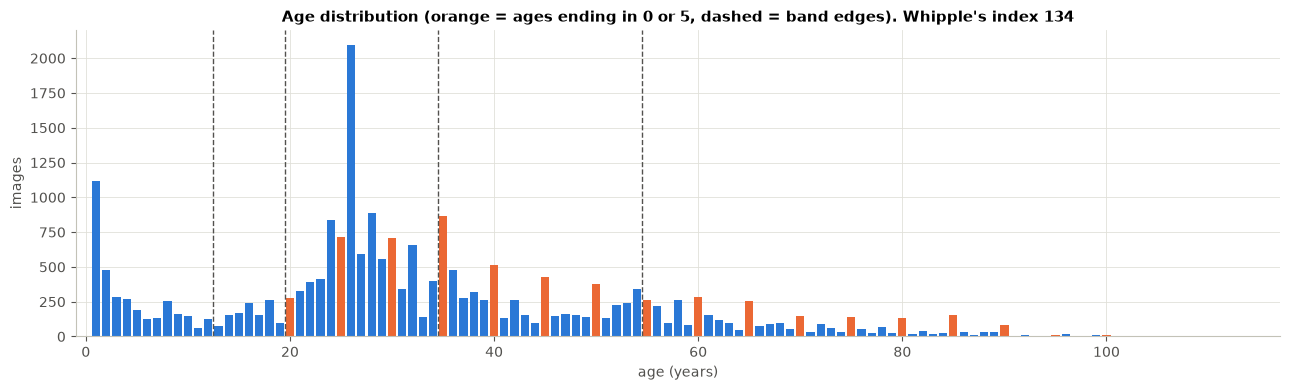

In [10]:
# ---------------------------------------------------------------
# 3.1 Age distribution and how rough the age labels are (age heaping)
# ---------------------------------------------------------------
age_counts = clean.groupBy("age").count().orderBy("age").toPandas()

# Whipple's index: the share of ages 23-62 ending in 0 or 5, compared with the 1 in 5 you'd
# expect if ages were exact. 100 = no rounding at all, 500 = every age ends in 0 or 5.
# People (and annotators) who guess an age round it, so a high value means estimated labels.
w = (clean.filter(F.col("age").between(23, 62))
     .agg(F.sum((F.col("age") % 5 == 0).cast("int")).alias("heaped"), F.count("*").alias("n")).first())
whipple = 100 * w["heaped"] / (w["n"] / 5)
print(f"Whipple's index (ages 23-62): {whipple:.0f}")

# How much bigger each round age is than the average of the four ages around it
lookup = age_counts.set_index("age")["count"]
heap_rows = []
for age in range(25, 75, 5):
    neighbours = [lookup.get(age + d, 0) for d in (-2, -1, 1, 2)]
    heap_rows.append({"age": age, "count": lookup.get(age, 0), "neighbour_avg": np.mean(neighbours),
                      "ratio": lookup.get(age, 0) / max(np.mean(neighbours), 1)})
heap_table = pd.DataFrame(heap_rows).round(2)
print(heap_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
heaped_age = (age_counts["age"] % 5 == 0) & (age_counts["age"] >= 20)
ax.bar(age_counts["age"], age_counts["count"], width=0.8,
       color=np.where(heaped_age, CAT_COLOURS[1], CAT_COLOURS[0]))
for edge in BAND_EDGES[1:-1]:
    ax.axvline(edge - 0.5, color=INK2, ls="--", lw=1)
ax.set(xlabel="age (years)", ylabel="images", title=f"Age distribution (orange = ages ending in 0 or 5, dashed = band edges). Whipple's index {whipple:.0f}")
ax.set_xlim(-1, age_counts["age"].max() + 1)
plt.tight_layout(); save_fig("02_age_distribution"); plt.show()

**Findings:** written from the real outputs after the full run.

 band_idx  band  count  share_%
        0  0-12   3359    14.57
        1 13-19   1144     4.96
        2 20-34   9331    40.47
        3 35-54   5701    24.73
        4   55+   3521    15.27
largest band / smallest band: 8.2 x
images labelled exactly [20, 35, 55]: 1,401 (6.1% of the data)


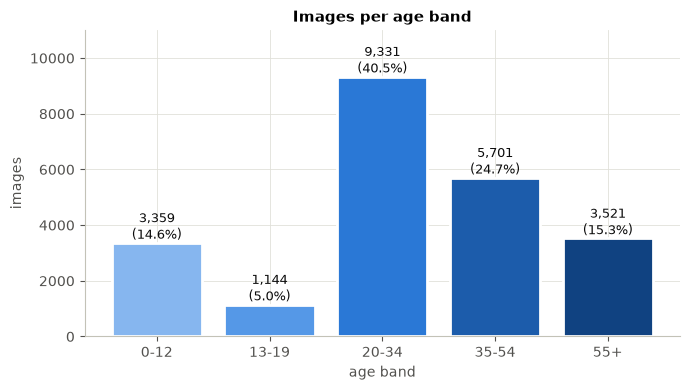

In [11]:
# ---------------------------------------------------------------
# 3.2 Class balance across the age bands and labels sitting on a band edge
# ---------------------------------------------------------------
band_counts = clean.groupBy("band_idx", "band").count().orderBy("band_idx").toPandas()
band_counts["share_%"] = (100 * band_counts["count"] / band_counts["count"].sum()).round(2)
print(band_counts.to_string(index=False))
print(f"largest band / smallest band: {band_counts['count'].max() / band_counts['count'].min():.1f} x")

# A guessed round age that is also the first age of a band (20, 35, 55) is the riskiest label:
# a person estimated at "35" could really be 33 and belong in the band below.
edge_ages = [e for e in BAND_EDGES[1:-1] if e % 5 == 0]
on_edge = clean.filter(F.col("age").isin(edge_ages)).count()
print(f"images labelled exactly {edge_ages}: {on_edge:,} ({100 * on_edge / clean.count():.1f}% of the data)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(band_counts["band"], band_counts["count"], color=BAND_COLOURS, edgecolor="white", linewidth=2)
for i, (n, s) in enumerate(zip(band_counts["count"], band_counts["share_%"])):
    ax.text(i, n, f"{n:,}\n({s:.1f}%)", ha="center", va="bottom", fontsize=9, color=INK)
ax.set(xlabel="age band", ylabel="images", title="Images per age band")
ax.margins(y=0.18)
plt.tight_layout(); save_fig("03_band_balance"); plt.show()

**Findings:** written from the real outputs after the full run.

band vs gender: Cramer's V = 0.191, p = 4.46e-180
       Male  Female
0-12   47.2    52.8
13-19  44.1    55.9
20-34  43.5    56.5
35-54  64.8    35.2
55+    61.8    38.2 

band vs race: Cramer's V = 0.179, p = 0.00e+00
       White  Black  Asian  Indian  Others
0-12    38.8    5.3   28.2    15.4    12.3
13-19   60.1   13.0    6.3    10.3    10.3
20-34   29.4   26.2   17.2    19.1     8.2
35-54   48.9   20.7    7.6    17.9     4.9
55+     65.5   13.1    8.9    11.4     1.0 



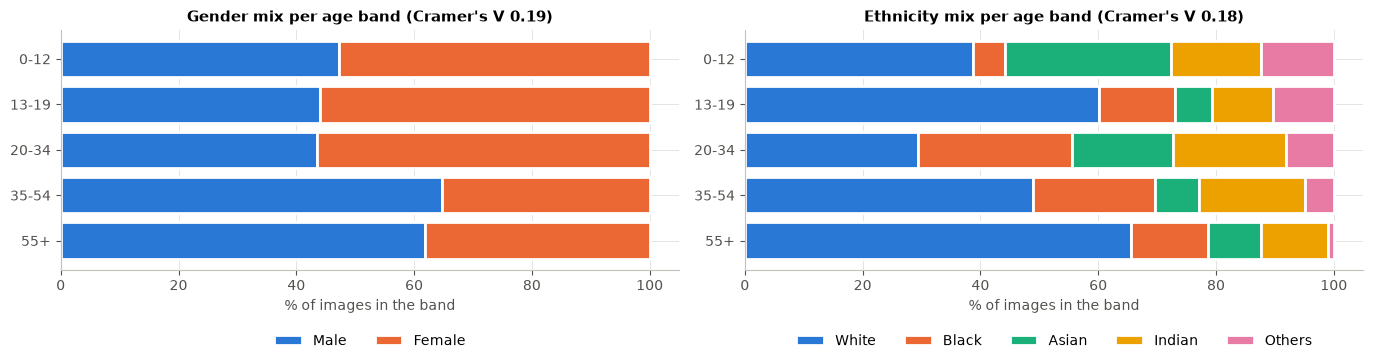

overall ethnicity mix (%):
White     42.6
Black     19.1
Asian     14.6
Indian    16.6
Others     7.0


In [12]:
# ---------------------------------------------------------------
# 3.3 Who is in each band: gender and ethnicity composition
# ---------------------------------------------------------------
def cramers_v(table):
    """Cramer's V effect size for a contingency table (0 = no association, 1 = perfect)."""
    chi2, p, _, _ = stats.chi2_contingency(table)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

comp = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (col, names) in zip(axes, [("gender", GENDER_NAMES), ("race", RACE_NAMES)]):
    # Counts per band and group are aggregated in Spark, then pivoted to a small table
    ct = (clean.groupBy("band_idx").pivot(col, list(names)).count().fillna(0)
          .orderBy("band_idx").toPandas().set_index("band_idx"))
    ct.index = BAND_NAMES
    ct.columns = [names[int(c)] for c in ct.columns]
    comp[col] = ct
    v, p = cramers_v(ct)
    print(f"band vs {col}: Cramer's V = {v:.3f}, p = {p:.2e}")
    shares = ct.div(ct.sum(axis=1), axis=0) * 100
    print(shares.round(1).to_string(), "\n")
    left = np.zeros(len(shares))
    for k, group in enumerate(shares.columns):
        ax.barh(shares.index, shares[group], left=left, color=CAT_COLOURS[k], edgecolor="white", linewidth=2, label=group)
        left += shares[group].values
    ax.invert_yaxis()
    label = "Ethnicity" if col == "race" else "Gender"
    ax.set(xlabel="% of images in the band", title=f"{label} mix per age band (Cramer's V {v:.2f})")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=len(shares.columns))
plt.tight_layout(); save_fig("04_band_composition"); plt.show()

print("overall ethnicity mix (%):")
print((100 * comp["race"].sum() / comp["race"].values.sum()).round(1).to_string())

**Findings:** written from the real outputs after the full run.

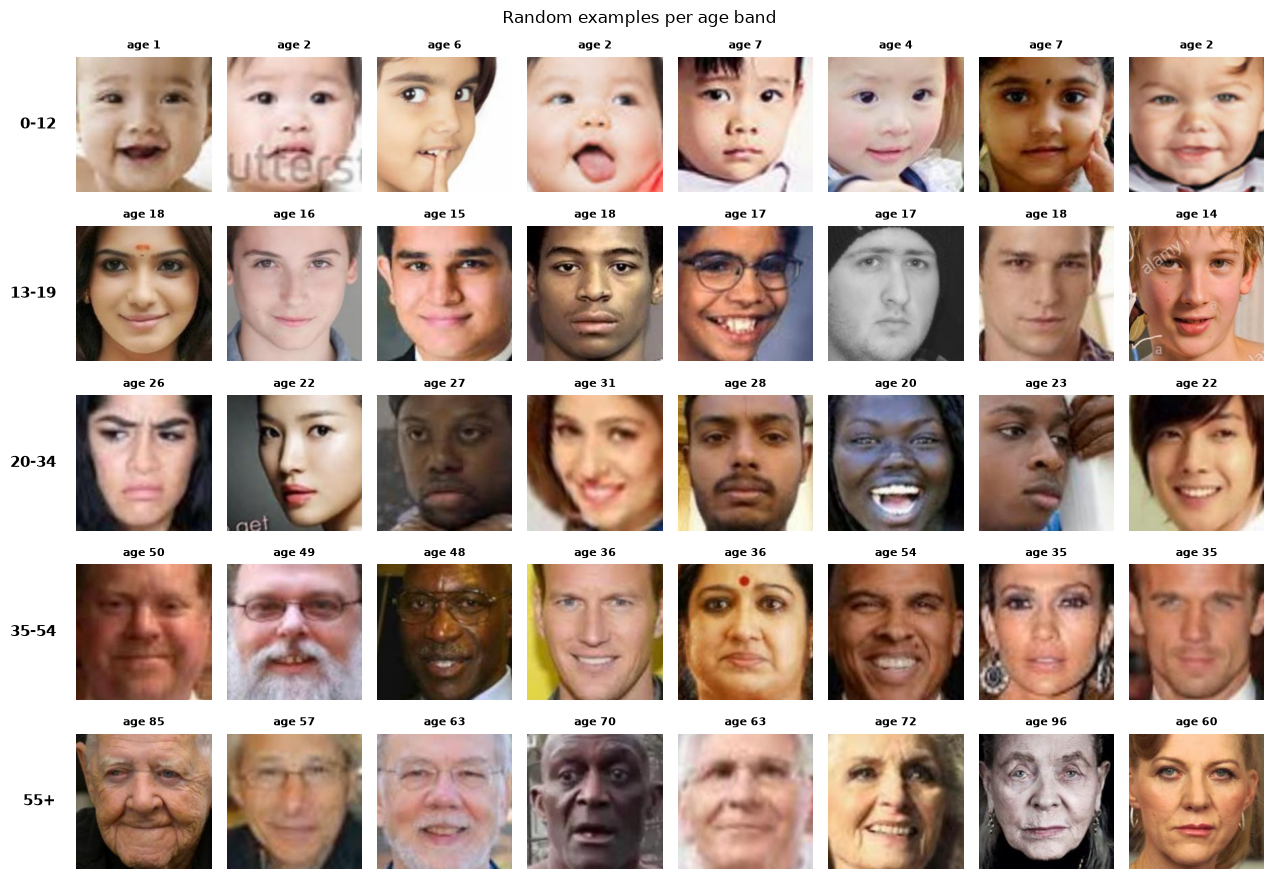

In [13]:
# ---------------------------------------------------------------
# 3.4 What the images look like: random examples per band
# ---------------------------------------------------------------
# A hash of the filename gives a random but repeatable sample of 8 images per band
per_band = 8
samples = (clean
           .withColumn("r", F.row_number().over(Window.partitionBy("band_idx").orderBy(F.xxhash64("filename", F.lit(SEED)))))
           .filter(F.col("r") <= per_band).select("band_idx", "filename", "age").toPandas())

fig, axes = plt.subplots(N_CLASSES, per_band, figsize=(1.6 * per_band, 1.8 * N_CLASSES))
for bi, grp in samples.groupby("band_idx"):
    for j, (_, row) in enumerate(grp.iterrows()):
        axes[bi, j].imshow(Image.open(f"{IMG_DIR}/{row.filename}"))
        axes[bi, j].set_title(f"age {row.age}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
for bi, name in enumerate(BAND_NAMES):
    axes[bi, 0].text(-0.15, 0.5, name, transform=axes[bi, 0].transAxes, ha="right", va="center", fontsize=11, weight="bold")
plt.suptitle("Random examples per age band")
plt.tight_layout(); save_fig("05_examples_per_band"); plt.show()

**Findings:** written from the real outputs after the full run.

### 3.5 The average face per band

Because the faces are aligned, averaging the 32 x 32 thumbnails pixel by pixel gives a meaningful "average face" for each band. The averaging runs in Spark: each thumbnail is exploded into one row per pixel position, and Spark averages each position per band. The second row shows how each band's average differs from the overall average, which shows where in the image the age information sits.

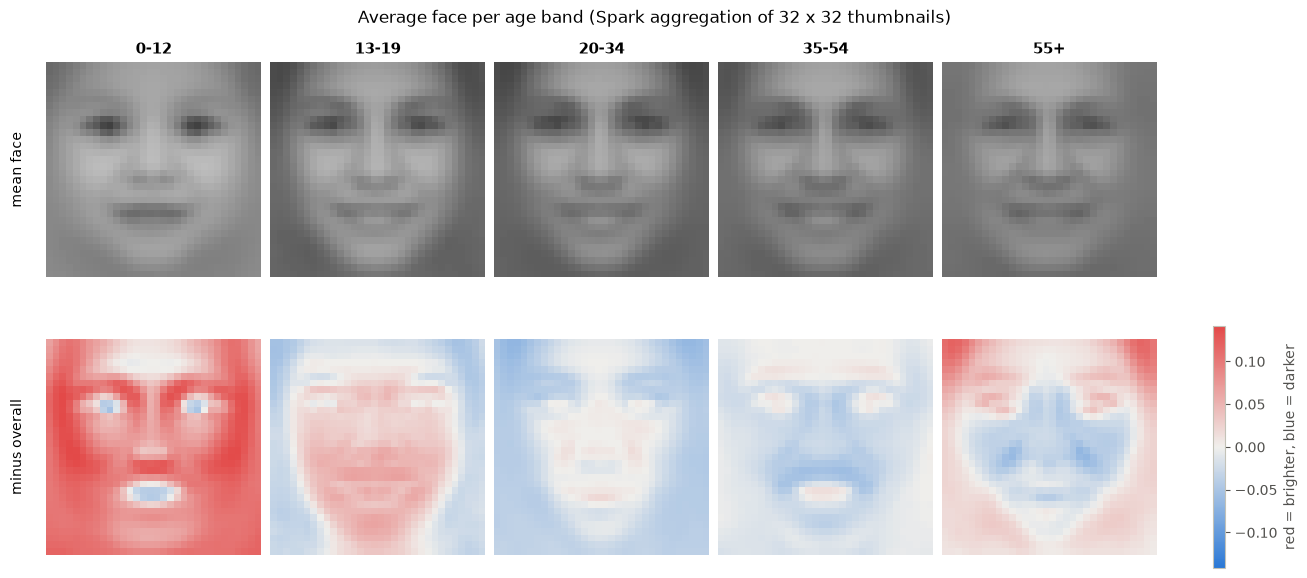

In [14]:
# ---------------------------------------------------------------
# 3.5 Mean face and difference from the overall mean, computed in Spark
# ---------------------------------------------------------------
pixel_means = (clean.select("band_idx", F.posexplode("thumb").alias("pos", "val"))
               .groupBy("band_idx", "pos").agg(F.avg("val").alias("val"))
               .toPandas().sort_values(["band_idx", "pos"]))
mean_faces = np.stack([pixel_means.loc[pixel_means.band_idx == b, "val"].values.reshape(THUMB, THUMB)
                       for b in range(N_CLASSES)])
# Weight each band's mean by its size to get the true overall mean face
weights = band_counts.sort_values("band_idx")["count"].values
overall = np.tensordot(weights / weights.sum(), mean_faces, axes=1)
diffs = mean_faces - overall
lim = np.abs(diffs).max()

fig, axes = plt.subplots(2, N_CLASSES, figsize=(2.6 * N_CLASSES, 5.8), layout="constrained")
for b in range(N_CLASSES):
    axes[0, b].imshow(mean_faces[b], cmap="gray", vmin=0, vmax=1)
    axes[0, b].set_title(f"{BAND_NAMES[b]}")
    im = axes[1, b].imshow(diffs[b], cmap=DIVERGING, vmin=-lim, vmax=lim)
    for r in range(2):
        axes[r, b].axis("off")
axes[0, 0].text(-0.1, 0.5, "mean face", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center")
axes[1, 0].text(-0.1, 0.5, "minus overall", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center")
fig.colorbar(im, ax=axes[1, :], shrink=0.9, label="red = brighter, blue = darker")
fig.suptitle("Average face per age band (Spark aggregation of 32 x 32 thumbnails)")
save_fig("06_mean_faces"); plt.show()

**Findings:** written from the real outputs after the full run.

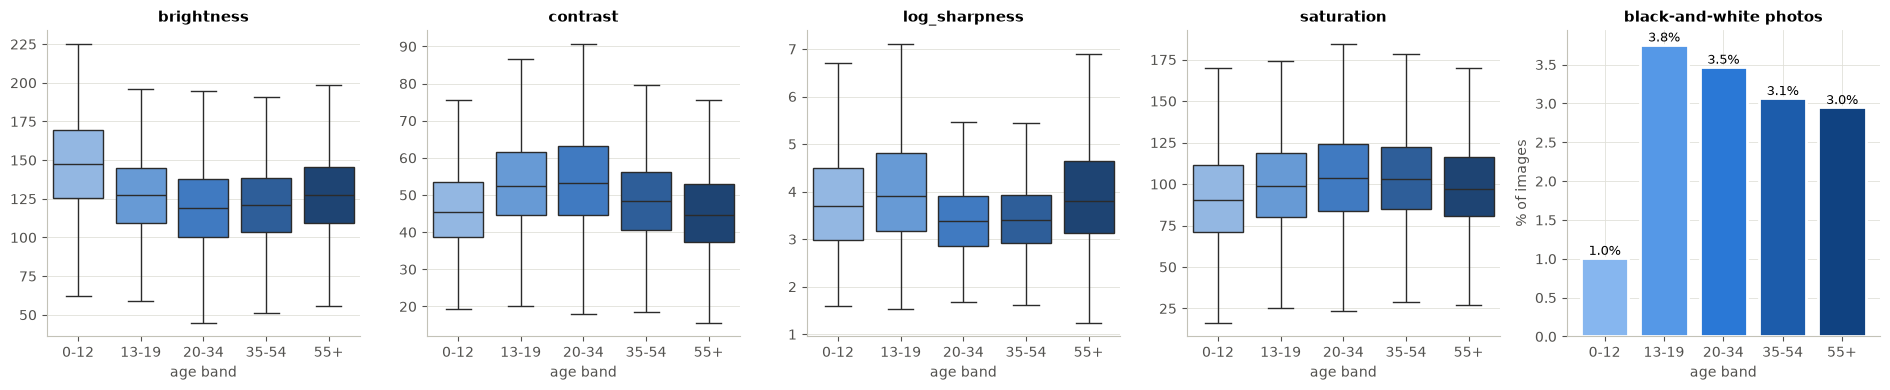

      measure           test  effect effect_type   p_value
   brightness Kruskal-Wallis  0.0906   epsilon^2  0.00e+00
     contrast Kruskal-Wallis  0.0743   epsilon^2  0.00e+00
      is_gray     chi-square  0.0492  Cramer's V  2.15e-11
log_sharpness Kruskal-Wallis  0.0400   epsilon^2 3.98e-198
   saturation Kruskal-Wallis  0.0233   epsilon^2 2.04e-111


In [15]:
# ---------------------------------------------------------------
# 3.6 Image-level measures by band and statistical tests
# ---------------------------------------------------------------
MEASURES = ["brightness", "contrast", "sharpness", "saturation"]
img_pd = clean.select("band_idx", "is_gray", "gender", "race", *MEASURES).toPandas()
# Sharpness is extremely right-skewed, so it is compared on a log scale
img_pd["log_sharpness"] = np.log1p(img_pd["sharpness"])
plot_measures = ["brightness", "contrast", "log_sharpness", "saturation"]

fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, m in zip(axes, plot_measures):
    # Saturation is meaningless for black-and-white photos (it is ~0), so they're left out of that panel
    data = img_pd[~img_pd.is_gray] if m == "saturation" else img_pd
    sns.boxplot(data=data, x="band_idx", y=m, hue="band_idx", palette=BAND_COLOURS, legend=False, showfliers=False, ax=ax)
    ax.set_xticks(range(N_CLASSES), BAND_NAMES); ax.set(xlabel="age band", ylabel="", title=m)
gray_share = img_pd.groupby("band_idx")["is_gray"].mean() * 100
axes[4].bar(BAND_NAMES, gray_share.values, color=BAND_COLOURS, edgecolor="white", linewidth=2)
for i, v in enumerate(gray_share.values):
    axes[4].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
axes[4].set(xlabel="age band", ylabel="% of images", title="black-and-white photos")
plt.tight_layout(); save_fig("07_image_measures_by_band"); plt.show()

# Kruskal-Wallis instead of ANOVA because none of these measures are normally distributed.
# Epsilon squared is its effect size (share of the rank variance explained by the band),
# because with 20 000+ images almost any difference will be "significant".
rows = []
for m in plot_measures:
    data = img_pd[~img_pd.is_gray] if m == "saturation" else img_pd
    groups = [g[m].values for _, g in data.groupby("band_idx")]
    h, p = stats.kruskal(*groups)
    n = len(data)
    rows.append({"measure": m, "test": "Kruskal-Wallis", "effect": round(h * (n + 1) / (n ** 2 - 1), 4), "effect_type": "epsilon^2", "p_value": f"{p:.2e}"})
v, p = cramers_v(pd.crosstab(img_pd.band_idx, img_pd.is_gray))
rows.append({"measure": "is_gray", "test": "chi-square", "effect": round(v, 4), "effect_type": "Cramer's V", "p_value": f"{p:.2e}"})
measure_tests = pd.DataFrame(rows).sort_values("effect", ascending=False)
print(measure_tests.to_string(index=False))
measure_tests.to_csv("outputs/image_measure_tests.csv", index=False)

**Findings:** written from the real outputs after the full run.

### 3.7 EDA findings and the decisions they lead to

Table written from the real outputs after the full run.

## 4. The Split and the Input Pipeline

The split is done in Spark, by **group** (from 2.3) and stratified by age band:
- Train: 70% of the groups in each band
- Validation: 15% (used for the ablation in Section 5, early stopping and choosing the model)
- Test: 15% (only used once per model, at the end)

Splitting by group means every near duplicate of a photo lands in the same split as the photo itself. Stratifying by band keeps the band mix the same in all three splits, which matters because the smallest band is a lot smaller than the biggest. Instead of `randomSplit`, each group is ranked by a hash of its ID with the seed, so the split comes out identical on every run and every machine.

In [16]:
# ---------------------------------------------------------------
# 4.1 Group-aware, band-stratified split in Spark
# ---------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

groups = (
    clean.groupBy("group_id")
    # a near-duplicate group whose members disagree on band is assigned by its youngest member
    .agg(F.min("band_idx").alias("band_idx"), F.count("*").alias("n_images"))
    .withColumn("u", F.percent_rank().over(
        Window.partitionBy("band_idx").orderBy(F.xxhash64("group_id", F.lit(SEED)))))
    .withColumn("split", F.when(F.col("u") < TRAIN_FRAC, "train")
                          .when(F.col("u") < TRAIN_FRAC + VAL_FRAC, "val")
                          .otherwise("test"))
)
clean = clean.join(groups.select("group_id", "split"), "group_id")
clean.cache()

split_table = (clean.groupBy("split").pivot("band", BAND_NAMES).count().fillna(0)
               .toPandas().set_index("split").loc[["train", "val", "test"]].astype(int))
split_table["total"] = split_table.sum(axis=1)
print(split_table.to_string())
print("\nband share per split (%):")
print((100 * split_table[BAND_NAMES].div(split_table["total"], axis=0)).round(1).to_string())

# Leakage check: no near-duplicate group may appear in more than one split
leaks = clean.groupBy("group_id").agg(F.countDistinct("split").alias("k")).filter("k > 1").count()
print(f"\ngroups split across train/val/test: {leaks}")
assert leaks == 0

       0-12  13-19  20-34  35-54   55+  total
split                                        
train  2350    799   6543   3997  2456  16145
val     507    170   1389    852   535   3453
test    502    175   1399    852   530   3458

band share per split (%):
       0-12  13-19  20-34  35-54   55+
split                                 
train  14.6    4.9   40.5   24.8  15.2
val    14.7    4.9   40.2   24.7  15.5
test   14.5    5.1   40.5   24.6  15.3

groups split across train/val/test: 0


**Findings:** written from the real outputs after the full run.

### 4.2 Handing over to TensorFlow

Spark's job ends here. The split manifest (one row per image with its filename, labels and split) is small, so it comes into pandas, and TensorFlow's `tf.data` reads the images straight from disk. Each image is decoded, resized with anti-aliasing (so shrinking it doesn't create jagged edges), stored as 8-bit integers in a memory cache (four times smaller than floats, so the whole training set fits in RAM) and served in shuffled batches. Pixel scaling to 0-1 happens inside the model, so a saved model can be given raw images.

In [17]:
# ---------------------------------------------------------------
# 4.2 Manifest to pandas and the tf.data input pipeline
# ---------------------------------------------------------------
manifest = (clean.select("filename", "age", "gender", "race", "band_idx", "is_gray", "split")
            .orderBy("filename").toPandas())
manifest.to_csv("outputs/split_manifest.csv", index=False)
train_df = manifest[manifest.split == "train"].reset_index(drop=True)
val_df = manifest[manifest.split == "val"].reset_index(drop=True)
test_df = manifest[manifest.split == "test"].reset_index(drop=True)
y_train, y_val, y_test = (d["band_idx"].values for d in (train_df, val_df, test_df))
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")

# TensorFlow only comes in now that Spark is done
import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(SEED)
# hide TensorFlow's retracing notices, which are about speed, not correctness
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible:", tf.config.list_physical_devices("GPU") or "none, training runs on the CPU")

AUTOTUNE = tf.data.AUTOTUNE
BATCH = 64

def load_image(path, size, gray):
    """Read, decode and resize one image, returned as uint8 so the cache stays small."""
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (size, size), method="bilinear", antialias=True)
    if gray:
        img = tf.image.rgb_to_grayscale(img)
    return tf.cast(tf.round(img), tf.uint8)

def make_dataset(frame, size, gray=False, shuffle=False):
    """tf.data pipeline for one split. Labels are one-hot so label smoothing and the macro-F1
    metric can be used. Evaluation sets are NOT shuffled, so predictions line up with `frame`."""
    paths = [f"{IMG_DIR}/{f}" for f in frame["filename"]]
    targets = tf.one_hot(frame["band_idx"].values, N_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((paths, targets))
    ds = ds.map(lambda p, y: (load_image(p, size, gray), y), num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train 16,145 | val 3,453 | test 3,458
TensorFlow 2.21.0 | Keras 3.15.1
GPUs visible: none, training runs on the CPU


## 5. Feature Selection for a CNN

The brief suggests p-values with backward and forward elimination. That worked in Part 2 because logistic regression uses a handful of hand-made columns, each with one coefficient and a p-value. It doesn't carry over to a CNN. The inputs are thousands of raw pixels, none of which means anything on its own, and the network learns its own features (edges, then textures like wrinkles, then face parts) in the convolution layers. There's no p-value for a convolution filter.

So for images, feature selection means choosing **what the network gets to see**: how many pixels (resolution) and which channels (colour or grayscale). I test this with an ablation, which is the CNN version of elimination. The same baseline network is trained briefly on four versions of the input and scored on the validation set:

| Variant | What it tests |
|---|---|
| RGB, 64 x 64 | the reference |
| Grayscale, 64 x 64 | removing colour (backward step): does colour carry age information, or mostly skin tone? |
| RGB, 32 x 32 | removing resolution (backward step): are fine details like wrinkles needed? |
| RGB, 96 x 96 | adding resolution (forward step): does more detail help enough to justify about twice the compute? |

The rule mirrors the p-value approach: keep the **cheapest input whose validation macro-F1 is within 0.01 of the best**. A feature (colour, extra pixels) only stays if dropping it costs real performance. The EDA tests in 3.6 back this up from the data side, since they show which image properties actually differ between bands.

In [18]:
# ---------------------------------------------------------------
# 5.1 Baseline architecture and a train-or-load helper
# ---------------------------------------------------------------
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, confusion_matrix,
                             precision_recall_fscore_support, classification_report)

# Set to True to retrain everything instead of loading models saved by an earlier run
FORCE_RETRAIN = False

def macro_f1_metric():
    """Macro-F1 tracked during training, so early stopping watches the same score I evaluate on."""
    return keras.metrics.F1Score(average="macro", name="macro_f1")

def build_baseline(input_shape, name="baseline"):
    """A deliberately plain CNN: three conv + max-pool blocks, flatten, one dense layer.
    No batch norm, no dropout, no augmentation, no class weights."""
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=["accuracy", macro_f1_metric()])
    return model

def train_or_load(build_fn, name, train_ds, val_ds, epochs, patience, class_weight=None, extra_callbacks=()):
    """Train a model and save it, or load the saved copy if it already exists. CPU training takes a
    while, so after a restart (or the laptop sleeping, like in Part 1) nothing has to be retrained."""
    model_path, hist_path = f"models/{name}.keras", f"models/{name}_history.json"
    if not FORCE_RETRAIN and os.path.exists(model_path) and os.path.exists(hist_path):
        print(f"{name}: loaded the saved model")
        with open(hist_path) as f:
            return keras.models.load_model(model_path), json.load(f)

    model = build_fn()
    # Early stopping on validation macro-F1, keeping the best weights seen
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max", patience=patience,
                                               restore_best_weights=True), *extra_callbacks]
    t0 = time.time()
    fit = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=class_weight,
                    callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in fit.history.items()}
    history["seconds"] = time.time() - t0
    history["best_epoch"] = int(np.argmax(history["val_macro_f1"])) + 1
    model.save(model_path)
    # Write to a temporary file and then rename it, so a crash mid-write can't leave a half-written
    # history file (that is what corrupted baseline_history.json in Part 1)
    with open(hist_path + ".tmp", "w") as f:
        json.dump(history, f)
    os.replace(hist_path + ".tmp", hist_path)
    print(f"{name}: best epoch {history['best_epoch']} of {len(history['loss'])}, {history['seconds'] / 60:.1f} min")
    return model, history

build_baseline((64, 64, 3)).summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,597 (4.36 MB)

 Trainable params: 1,142,597 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
253/253 - 43s - 170ms/step - accuracy: 0.5589 - loss: 1.0814 - macro_f1: 0.4371 - val_accuracy: 0.6423 - val_loss: 0.9527 - val_macro_f1: 0.5204
Epoch 2/12
253/253 - 21s - 83ms/step - accuracy: 0.6642 - loss: 0.8375 - macro_f1: 0.5510 - val_accuracy: 0.6719 - val_loss: 0.8190 - val_macro_f1: 0.5594
Epoch 3/12
253/253 - 21s - 82ms/step - accuracy: 0.6958 - loss: 0.7516 - macro_f1: 0.6029 - val_accuracy: 0.6890 - val_loss: 0.7849 - val_macro_f1: 0.5773
Epoch 4/12
253/253 - 21s - 82ms/step - accuracy: 0.7179 - loss: 0.6869 - macro_f1: 0.6361 - val_accuracy: 0.6968 - val_loss: 0.7237 - val_macro_f1: 0.6281
Epoch 5/12
253/253 - 21s - 83ms/step - accuracy: 0.7455 - loss: 0.6295 - macro_f1: 0.6839 - val_accuracy: 0.6994 - val_loss: 0.7527 - val_macro_f1: 0.6204
Epoch 6/12
253/253 - 21s - 82ms/step - accuracy: 0.7622 - loss: 0.5821 - macro_f1: 0.7134 - val_accuracy: 0.6919 - val_loss: 0.7958 - val_macro_f1: 0.6396
Epoch 7/12
253/253 - 21s - 82ms/step - accuracy: 0.7806 - loss: 0.537

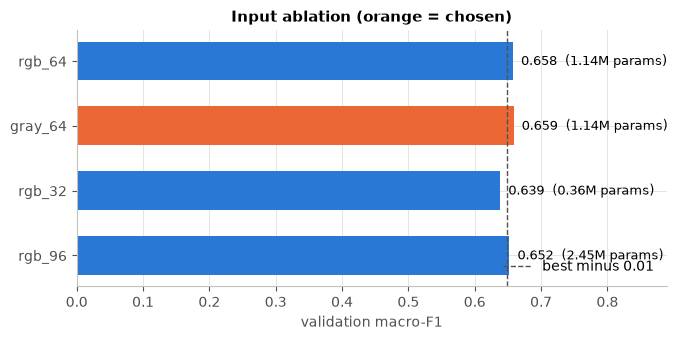

In [19]:
# ---------------------------------------------------------------
# 5.2 Input ablation: colour and resolution
# ---------------------------------------------------------------
VARIANTS = {"rgb_64": (64, False), "gray_64": (64, True), "rgb_32": (32, False), "rgb_96": (96, False)}
ABLATION_EPOCHS, ABLATION_PATIENCE = 12, 3

ablation_rows = []
for name, (size, gray) in VARIANTS.items():
    shape = (size, size, 1 if gray else 3)
    tr = make_dataset(train_df, size, gray, shuffle=True)
    va = make_dataset(val_df, size, gray)
    model, hist = train_or_load(lambda: build_baseline(shape, name=f"ablation_{name}"), f"ablation_{name}",
                                tr, va, ABLATION_EPOCHS, ABLATION_PATIENCE)
    pred = model.predict(va, verbose=0).argmax(axis=1)
    ablation_rows.append({"variant": name, "size": size, "channels": shape[2],
                          "input_values": size * size * shape[2], "params": model.count_params(),
                          "best_epoch": hist["best_epoch"],
                          "sec_per_epoch": round(hist["seconds"] / len(hist["loss"]), 1),
                          "val_accuracy": accuracy_score(y_val, pred),
                          "val_macro_f1": f1_score(y_val, pred, average="macro")})
ablation = pd.DataFrame(ablation_rows)

# Keep the cheapest input within 0.01 macro-F1 of the best one
TOLERANCE = 0.01
best_f1 = ablation["val_macro_f1"].max()
chosen = ablation[ablation["val_macro_f1"] >= best_f1 - TOLERANCE].sort_values("input_values").iloc[0]
IMG_SIZE, GRAY = int(chosen["size"]), bool(chosen["channels"] == 1)
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, 1 if GRAY else 3)
print(ablation.round(4).to_string(index=False))
print(f"\nchosen input: {chosen['variant']} -> {INPUT_SHAPE}")
ablation.to_csv("outputs/ablation.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
colours = [CAT_COLOURS[1] if v == chosen["variant"] else CAT_COLOURS[0] for v in ablation["variant"]]
ax.barh(ablation["variant"], ablation["val_macro_f1"], color=colours, height=0.6)
ax.axvline(best_f1 - TOLERANCE, color=INK2, ls="--", lw=1, label="best minus 0.01")
for i, (f1v, p) in enumerate(zip(ablation["val_macro_f1"], ablation["params"])):
    ax.text(f1v, i, f"  {f1v:.3f}  ({p / 1e6:.2f}M params)", va="center", fontsize=9)
ax.invert_yaxis(); ax.margins(x=0.35)
ax.set(xlabel="validation macro-F1", title="Input ablation (orange = chosen)"); ax.legend(loc="lower right")
plt.tight_layout(); save_fig("08_input_ablation"); plt.show()

**Findings:** written from the real outputs after the full run.

## 6. Baseline CNN

The baseline uses the input chosen in Section 5 and the plain architecture from 5.1, now trained properly (up to 30 epochs, stopping once validation macro-F1 hasn't improved for 6 epochs):

| Setting | Value | Why |
|---|---|---|
| Layers | 3 x (3 x 3 conv + ReLU, 2 x 2 max-pool) with 32, 64, 128 filters, then flatten, dense 128, softmax 5 | Small enough to train on a CPU, deep enough to learn edges, then textures, then face parts |
| Optimiser | Adam, learning rate 0.001 | Standard default that adapts the step size per weight (Kingma and Ba, 2015) |
| Loss | categorical cross-entropy | Standard for single-label multi-class problems |
| Batch size | 64 | Stable gradients without running out of RAM |
| Regularisation | none | On purpose, so the improved model can show what each addition fixes |
| Class weights | none | Same reason, so the effect of the imbalance shows up |

My expectation is that it will overfit (the flatten layer alone holds most of the parameters) and lean towards the big 20-34 band. If it does, those are the weaknesses the improved model has to fix.

In [20]:
# ---------------------------------------------------------------
# 6.1 Train the baseline on the chosen input
# ---------------------------------------------------------------
BASE_EPOCHS, BASE_PATIENCE = 30, 6

train_ds = make_dataset(train_df, IMG_SIZE, GRAY, shuffle=True)
val_ds = make_dataset(val_df, IMG_SIZE, GRAY)
test_ds = make_dataset(test_df, IMG_SIZE, GRAY)

baseline, base_hist = train_or_load(lambda: build_baseline(INPUT_SHAPE), "baseline",
                                    train_ds, val_ds, BASE_EPOCHS, BASE_PATIENCE)

Epoch 1/30
253/253 - 38s - 150ms/step - accuracy: 0.5542 - loss: 1.0892 - macro_f1: 0.4339 - val_accuracy: 0.6264 - val_loss: 0.9634 - val_macro_f1: 0.5168
Epoch 2/30
253/253 - 22s - 87ms/step - accuracy: 0.6590 - loss: 0.8610 - macro_f1: 0.5464 - val_accuracy: 0.6727 - val_loss: 0.8146 - val_macro_f1: 0.5620
Epoch 3/30
253/253 - 22s - 87ms/step - accuracy: 0.6842 - loss: 0.7771 - macro_f1: 0.5848 - val_accuracy: 0.6759 - val_loss: 0.7922 - val_macro_f1: 0.5594
Epoch 4/30
253/253 - 22s - 88ms/step - accuracy: 0.7088 - loss: 0.7144 - macro_f1: 0.6243 - val_accuracy: 0.6924 - val_loss: 0.7545 - val_macro_f1: 0.6230
Epoch 5/30
253/253 - 22s - 87ms/step - accuracy: 0.7263 - loss: 0.6621 - macro_f1: 0.6579 - val_accuracy: 0.6872 - val_loss: 0.7804 - val_macro_f1: 0.5954
Epoch 6/30
253/253 - 22s - 87ms/step - accuracy: 0.7465 - loss: 0.6165 - macro_f1: 0.6882 - val_accuracy: 0.6985 - val_loss: 0.7617 - val_macro_f1: 0.6203
Epoch 7/30
253/253 - 22s - 87ms/step - accuracy: 0.7657 - loss: 0.568

## 7. Evaluating the Baseline

| Metric | Why I'm using it |
|---|---|
| Accuracy | Reported for completeness, next to a "always guess the biggest band" model, because on imbalanced bands it flatters a model that ignores the small ones |
| Macro-F1 | My main metric. It averages F1 over the five bands equally, so the small teenager band counts as much as the big 20-34 band |
| Per-band precision and recall | Shows which bands get missed (recall) and which get over-predicted (precision) |
| Within-one-band accuracy | The bands are ordered, so calling a 36-year-old "20-34" is a much smaller mistake than calling them "0-12". With rough, rounded age labels (3.1), some neighbouring-band errors are label noise rather than model error |
| Quadratic weighted kappa | Agreement between predicted and true band that punishes errors by the square of how many bands apart they are (Cohen, 1968). 0 = chance, 1 = perfect |
| Confusion matrix | The raw picture of which bands get mixed up, shown as row percentages (each row is a true band) |
| Learning curves | Training vs validation loss and macro-F1 per epoch, to spot overfitting |

In [21]:
# ---------------------------------------------------------------
# 7.1 Evaluation and plotting helpers
# ---------------------------------------------------------------
def scores(y, yhat, name):
    """All the headline metrics for one set of predictions."""
    return {"model": name, "accuracy": accuracy_score(y, yhat),
            "macro_f1": f1_score(y, yhat, average="macro"),
            "weighted_f1": f1_score(y, yhat, average="weighted"),
            "within_one_band": np.mean(np.abs(y - yhat) <= 1),
            "quadratic_kappa": cohen_kappa_score(y, yhat, weights="quadratic")}

def evaluate(model, ds, frame, name, fig_name=None):
    """Score a model on one split. With fig_name, also plot the confusion matrix and per-band P/R/F1."""
    probs = model.predict(ds, verbose=0)
    y, yhat = frame["band_idx"].values, probs.argmax(axis=1)
    m = scores(y, yhat, name)
    if fig_name:
        fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
        cm = confusion_matrix(y, yhat, labels=range(N_CLASSES))
        pct = 100 * cm / cm.sum(axis=1, keepdims=True)
        annot = np.array([[f"{p:.0f}%\n({c:,})" for p, c in zip(pr, cr)] for pr, cr in zip(pct, cm)])
        sns.heatmap(pct, annot=annot, fmt="", cmap=SEQ_BLUE, vmin=0, vmax=100, cbar=False, ax=axes[0],
                    xticklabels=BAND_NAMES, yticklabels=BAND_NAMES, linewidths=2, linecolor="white")
        axes[0].set(xlabel="predicted band", ylabel="true band", title=f"{name}: confusion matrix (row %)")
        p, r, f, _ = precision_recall_fscore_support(y, yhat, labels=range(N_CLASSES), zero_division=0)
        xs = np.arange(N_CLASSES)
        for k, (vals, lab) in enumerate([(p, "precision"), (r, "recall"), (f, "F1")]):
            axes[1].bar(xs + (k - 1) * 0.27, vals, width=0.25, color=CAT_COLOURS[k], label=lab)
        axes[1].set_xticks(xs, BAND_NAMES); axes[1].set_ylim(0, 1)
        axes[1].set(xlabel="true band", title=f"{name}: per-band scores (macro-F1 {m['macro_f1']:.3f})")
        axes[1].legend(ncol=3, loc="upper center")
        plt.tight_layout(); save_fig(fig_name); plt.show()
    return m, probs

def plot_history(history, name, fig_name):
    """Loss and macro-F1 per epoch for train and validation, with the kept epoch marked."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key in zip(axes, ["loss", "macro_f1"]):
        ax.plot(range(1, len(history[key]) + 1), history[key], color=CAT_COLOURS[0], lw=2, label="train")
        ax.plot(range(1, len(history[key]) + 1), history[f"val_{key}"], color=CAT_COLOURS[1], lw=2, label="validation")
        ax.axvline(history["best_epoch"], color=INK2, ls=":", label=f"kept epoch {history['best_epoch']}")
        ax.set(xlabel="epoch", title=f"{name}: {key.replace('_', '-')}"); ax.legend()
    plt.tight_layout(); save_fig(fig_name); plt.show()

# The "always guess the biggest training band" model, for context
majority_band = int(pd.Series(y_train).mode()[0])
m_majority = scores(y_test, np.full_like(y_test, majority_band), f"Always '{BAND_NAMES[majority_band]}'")

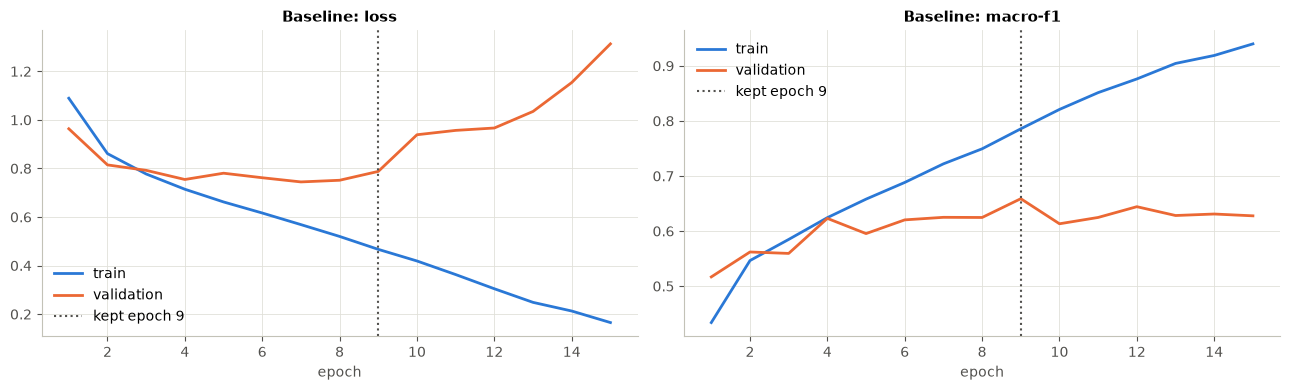

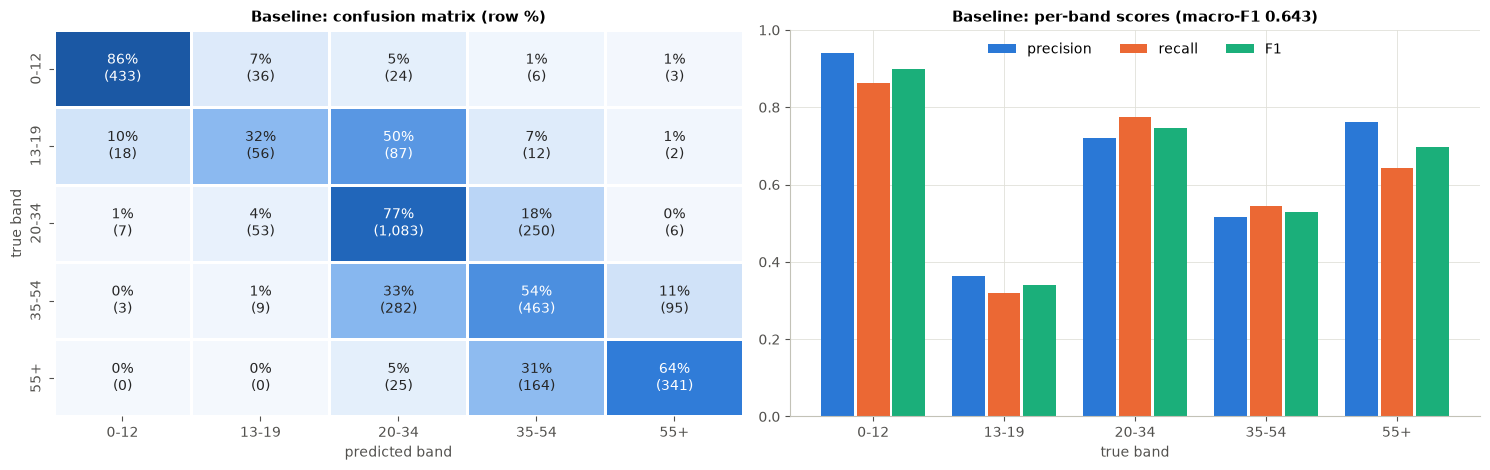

                accuracy  macro_f1  weighted_f1  within_one_band  quadratic_kappa
model                                                                            
Always '20-34'    0.4046    0.1152       0.2331           0.7016           0.0000
Baseline (val)    0.6982    0.6587       0.7005           0.9731           0.8466
Baseline          0.6871    0.6429       0.6875           0.9719           0.8464

              precision    recall  f1-score   support

        0-12      0.939     0.863     0.899       502
       13-19      0.364     0.320     0.340       175
       20-34      0.722     0.774     0.747      1399
       35-54      0.517     0.543     0.530       852
         55+      0.763     0.643     0.698       530

    accuracy                          0.687      3458
   macro avg      0.661     0.629     0.643      3458
weighted avg      0.691     0.687     0.688      3458



In [22]:
# ---------------------------------------------------------------
# 7.2 Baseline results
# ---------------------------------------------------------------
plot_history(base_hist, "Baseline", "09_baseline_learning_curves")
m_base_val, _ = evaluate(baseline, val_ds, val_df, "Baseline (val)")
m_base_test, base_probs = evaluate(baseline, test_ds, test_df, "Baseline", fig_name="10_baseline_evaluation")

print(pd.DataFrame([m_majority, m_base_val, m_base_test]).set_index("model").round(4).to_string())
print()
print(classification_report(y_test, base_probs.argmax(axis=1), target_names=BAND_NAMES, digits=3))

**Findings:** written from the real outputs after the full run.

## 8. Improved Model (Retraining)

Every change targets a weakness of the baseline or a finding from the EDA:

| Change | Why |
|---|---|
| Data augmentation: horizontal flips, small rotations (±18°), zoom and shifts (±10%), brightness and contrast changes | Every training epoch sees slightly different versions of each face, which fights overfitting. The ranges stay small because the faces are aligned, so big shifts would create faces that never occur (Shorten and Khoshgoftaar, 2019). Brightness and contrast changes stop the model from using lighting differences between bands (3.6) as a shortcut |
| Random grayscale (20% of training images, colour input only) | Black-and-white photos are not spread evenly over the bands (3.6), so the model could learn "black and white means old" instead of reading the face. Turning random training photos gray breaks that shortcut |
| Batch normalisation after every convolution (momentum 0.9) | Keeps each layer's inputs on a stable scale, which speeds up and steadies training (Ioffe and Szegedy, 2015). The lower momentum makes the running averages used at prediction time catch up faster |
| A 4th conv block (256 filters) and global average pooling instead of flatten | Pooling replaces the huge flatten-to-dense layer that holds most of the baseline's parameters, so the model has far fewer weights to overfit with |
| Dropout (0.1-0.25 after the conv blocks, 0.4 before the classifier) and L2 weight decay (0.0001) | Standard regularisation against memorising the training set (Srivastava et al., 2014) |
| Balanced class weights | Each band contributes equally to the loss, so the small bands can't be ignored |
| Label smoothing (0.1) | The targets become 0.92 for the true band and 0.02 for the others instead of 1 and 0. The age labels are rounded estimates (3.1), so telling the model to be 100% sure of a label that might be wrong is a bad idea (Szegedy et al., 2016) |
| Halve the learning rate when validation macro-F1 stalls for 4 epochs, up to 50 epochs with patience 10 | Big steps early on and fine steps once progress slows, with a longer budget because augmentation makes the model learn more slowly |

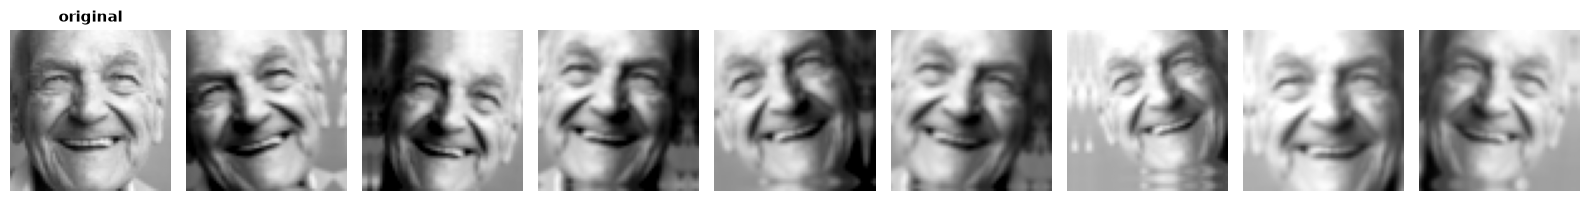

In [23]:
# ---------------------------------------------------------------
# 8.1 Augmentation layers, including a custom random grayscale layer
# ---------------------------------------------------------------
@keras.saving.register_keras_serializable(package="pdan8412")
class RandomGrayscale(layers.Layer):
    """During training, turn a random share of colour images into grayscale (kept as 3 channels).
    Does nothing at prediction time."""
    def __init__(self, rate=0.2, **kwargs):
        super().__init__(**kwargs)
        self.rate = rate

    def call(self, x, training=None):
        if not training:
            return x
        gray = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x))
        # one coin flip per image in the batch
        flip = tf.cast(tf.random.uniform((tf.shape(x)[0], 1, 1, 1)) < self.rate, x.dtype)
        return flip * gray + (1 - flip) * x

    def get_config(self):
        return {**super().get_config(), "rate": self.rate}

def augmentation_block(gray_input):
    """All augmentation works on pixels already scaled to 0-1."""
    steps = [
        layers.RandomFlip("horizontal"),
        # 0.05 of a full turn = 18 degrees
        layers.RandomRotation(0.05, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
        layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
        layers.RandomBrightness(0.15, value_range=(0, 1)),
        layers.RandomContrast(0.2, value_range=(0, 1)),
    ]
    if not gray_input:
        steps.append(RandomGrayscale(0.2))
    return keras.Sequential(steps, name="augmentation")

# Preview: one training image and eight augmented versions of it
preview_aug = augmentation_block(GRAY)
sample_img = tf.cast(load_image(f"{IMG_DIR}/{train_df.filename[0]}", IMG_SIZE, GRAY), tf.float32)[None] / 255.0
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(sample_img[0].numpy().squeeze(), cmap="gray" if GRAY else None); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(np.clip(preview_aug(sample_img, training=True)[0].numpy().squeeze(), 0, 1), cmap="gray" if GRAY else None)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); save_fig("11_augmentation_preview"); plt.show()

class weights: {'0-12': 1.37, '13-19': 4.04, '20-34': 0.49, '35-54': 0.81, '55+': 1.31}
parameters: improved 422,821 vs baseline 1,142,021
Epoch 1/50
253/253 - 103s - 406ms/step - accuracy: 0.2886 - loss: 1.6308 - macro_f1: 0.2731 - val_accuracy: 0.2795 - val_loss: 1.5294 - val_macro_f1: 0.2553 - learning_rate: 0.0010
Epoch 2/50
253/253 - 100s - 393ms/step - accuracy: 0.3607 - loss: 1.4680 - macro_f1: 0.3511 - val_accuracy: 0.3556 - val_loss: 1.4254 - val_macro_f1: 0.3710 - learning_rate: 0.0010
Epoch 3/50
253/253 - 97s - 383ms/step - accuracy: 0.3994 - loss: 1.4122 - macro_f1: 0.3886 - val_accuracy: 0.2288 - val_loss: 1.9127 - val_macro_f1: 0.1842 - learning_rate: 0.0010
Epoch 4/50
253/253 - 96s - 381ms/step - accuracy: 0.4282 - loss: 1.3718 - macro_f1: 0.4151 - val_accuracy: 0.3412 - val_loss: 1.6493 - val_macro_f1: 0.2691 - learning_rate: 0.0010
Epoch 5/50
253/253 - 97s - 384ms/step - accuracy: 0.4526 - loss: 1.3326 - macro_f1: 0.4396 - val_accuracy: 0.4567 - val_loss: 1.3930 - val_

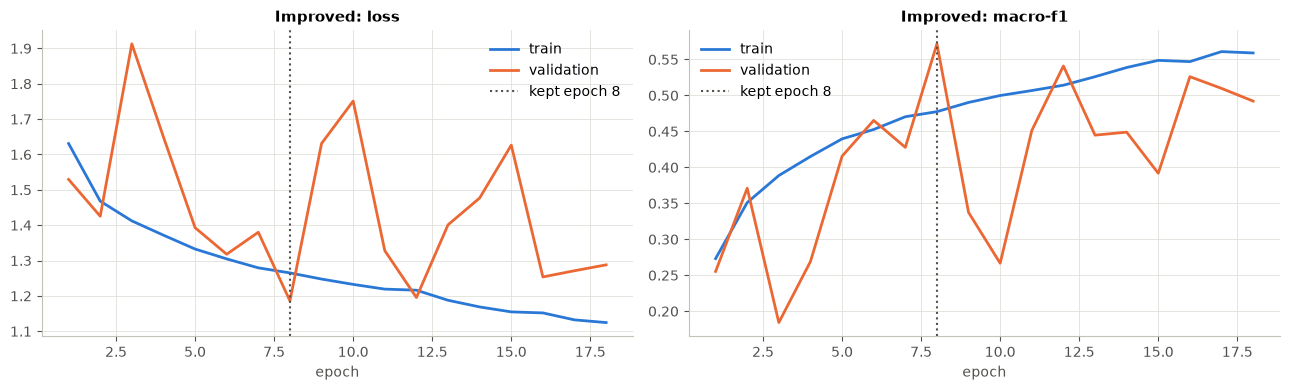

In [24]:
# ---------------------------------------------------------------
# 8.2 Improved architecture and training
# ---------------------------------------------------------------
from sklearn.utils.class_weight import compute_class_weight

IMP_EPOCHS, IMP_PATIENCE = 50, 10
LABEL_SMOOTHING, WEIGHT_DECAY = 0.1, 1e-4

def build_improved(input_shape, name="improved"):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(WEIGHT_DECAY)
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = augmentation_block(input_shape[-1] == 1)(x)
    for i, (filters, drop) in enumerate([(32, 0.1), (64, 0.15), (128, 0.2), (256, 0.25)]):
        # no bias, because batch norm right after it has its own shift
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
        # momentum 0.9 (default 0.99) lets the running averages used at prediction time settle
        # within the first epoch instead of lagging behind the weights for several epochs
        x = layers.BatchNormalization(momentum=0.9)(x)
        # the last activation is named so Grad-CAM in 9.2 can find it
        x = layers.Activation("relu", name="last_conv_act" if i == 3 else None)(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
                  metrics=["accuracy", macro_f1_metric()])
    return model

# "balanced": weight = total images / (number of bands x images in this band)
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
class_weights = dict(enumerate(cw))
print("class weights:", {BAND_NAMES[k]: round(float(v), 2) for k, v in class_weights.items()})

tmp_model = build_improved(INPUT_SHAPE)
print(f"parameters: improved {tmp_model.count_params():,} vs baseline {baseline.count_params():,}")
del tmp_model

reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max", factor=0.5,
                                              patience=4, min_lr=1e-5, verbose=1)
improved, imp_hist = train_or_load(lambda: build_improved(INPUT_SHAPE), "improved", train_ds, val_ds,
                                   IMP_EPOCHS, IMP_PATIENCE, class_weight=class_weights,
                                   extra_callbacks=[reduce_lr])
plot_history(imp_hist, "Improved", "12_improved_learning_curves")

**Findings:** written from the real outputs after the full run.

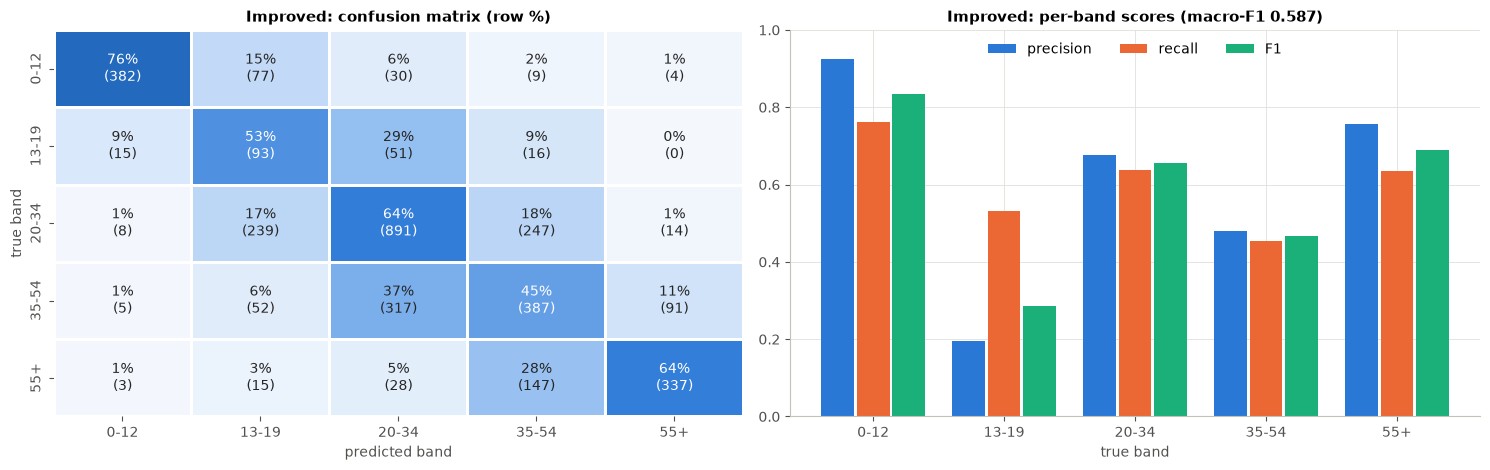

                accuracy  macro_f1  weighted_f1  within_one_band  quadratic_kappa   params  epochs_trained
model                                                                                                     
Always '20-34'    0.4046    0.1152       0.2331           0.7016           0.0000        0               0
Baseline          0.6871    0.6429       0.6875           0.9719           0.8464  1142021              15
Improved          0.6044    0.5868       0.6220           0.9468           0.7786   422821              18

              precision    recall  f1-score   support

        0-12      0.925     0.761     0.835       502
       13-19      0.195     0.531     0.286       175
       20-34      0.677     0.637     0.656      1399
       35-54      0.480     0.454     0.467       852
         55+      0.756     0.636     0.691       530

    accuracy                          0.604      3458
   macro avg      0.607     0.604     0.587      3458
weighted avg      0.652     0.

In [25]:
# ---------------------------------------------------------------
# 8.3 Final test-set evaluation: baseline vs improved
# ---------------------------------------------------------------
m_imp_val, _ = evaluate(improved, val_ds, val_df, "Improved (val)")
m_imp_test, imp_probs = evaluate(improved, test_ds, test_df, "Improved", fig_name="13_improved_evaluation")

comparison = pd.DataFrame([m_majority, m_base_test, m_imp_test]).set_index("model")
comparison["params"] = [0, baseline.count_params(), improved.count_params()]
comparison["epochs_trained"] = [0, len(base_hist["loss"]), len(imp_hist["loss"])]
print(comparison.round(4).to_string())
print()
print(classification_report(y_test, imp_probs.argmax(axis=1), target_names=BAND_NAMES, digits=3))
comparison.to_csv("outputs/test_comparison.csv")

**Findings:** written from the real outputs after the full run.

## 9. Interpreting the Improved Model

Good overall scores aren't enough for a system that's meant to end up recognising faces at the publisher's premises. Three questions matter:
1. **Does it work equally well for everyone?** Commercial face systems have been shown to be far less accurate for some demographic groups than others (Buolamwini and Gebru, 2018). In South Africa that's a serious issue, and biometric data counts as special personal information under POPIA (Republic of South Africa, 2013).
2. **What is it looking at?** Grad-CAM (Selvaraju et al., 2017) highlights the parts of the image that pushed the model towards its answer. It should be the face (eyes, skin texture, hair), not the background.
3. **Where does it go wrong?** Mistakes near a band edge are partly label noise. Mistakes far from an edge are real model errors.

                      macro_f1          within_one_band         
model                 Baseline Improved        Baseline Improved
attribute group  n                                              
gender    Female 1605    0.638    0.561           0.972    0.935
          Male   1853    0.638    0.603           0.972    0.957
race      Asian  474     0.630    0.571           0.985    0.951
          Black  697     0.560    0.501           0.970    0.956
          Indian 585     0.605    0.552           0.971    0.945
          Others 239     0.592    0.541           0.987    0.971
          White  1463    0.642    0.601           0.967    0.938
gender: macro-F1 gap between best and worst group = 0.042
race: macro-F1 gap between best and worst group = 0.100


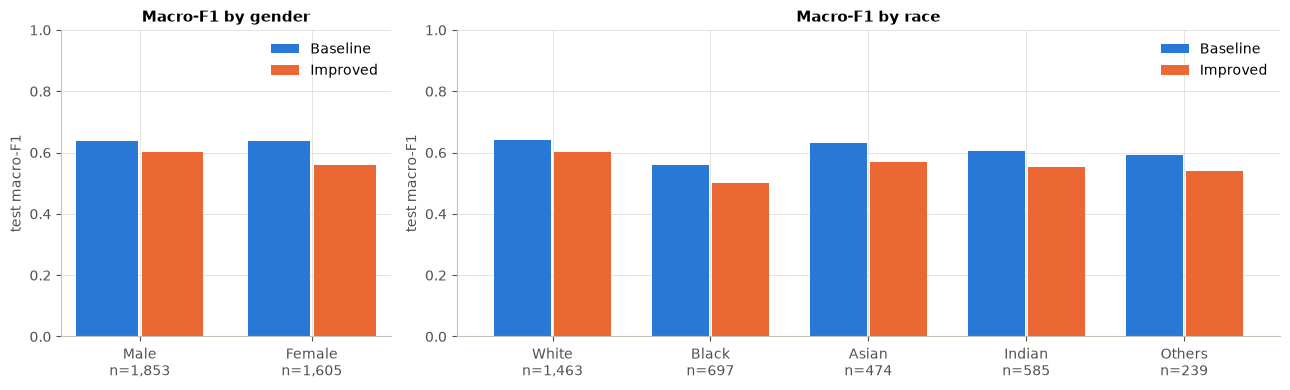

In [26]:
# ---------------------------------------------------------------
# 9.1 Fairness audit: performance per gender and ethnicity group (test set)
# ---------------------------------------------------------------
audit = test_df.copy()
audit["pred_base"] = base_probs.argmax(axis=1)
audit["pred_imp"] = imp_probs.argmax(axis=1)

fair_rows = []
for col, names in [("gender", GENDER_NAMES), ("race", RACE_NAMES)]:
    for code_, label in names.items():
        g = audit[audit[col] == code_]
        for model_name, pred_col in [("Baseline", "pred_base"), ("Improved", "pred_imp")]:
            row = scores(g["band_idx"].values, g[pred_col].values, model_name)
            fair_rows.append({"attribute": col, "group": label, "n": len(g), **row})
fairness = pd.DataFrame(fair_rows)
fairness.to_csv("outputs/fairness_audit.csv", index=False)
print(fairness.pivot_table(index=["attribute", "group", "n"], columns="model",
                           values=["macro_f1", "within_one_band"]).round(3).to_string())

imp_fair = fairness[fairness.model == "Improved"]
for col in ["gender", "race"]:
    sub = imp_fair[imp_fair.attribute == col]
    print(f"{col}: macro-F1 gap between best and worst group = {sub.macro_f1.max() - sub.macro_f1.min():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 5]})
for ax, col in zip(axes, ["gender", "race"]):
    sub = fairness[fairness.attribute == col]
    grp = sub["group"].unique()
    xs = np.arange(len(grp))
    for k, model_name in enumerate(["Baseline", "Improved"]):
        vals = sub[sub.model == model_name].set_index("group").loc[grp, "macro_f1"]
        ax.bar(xs + (k - 0.5) * 0.38, vals, width=0.36, color=CAT_COLOURS[k], label=model_name)
    ns = sub.drop_duplicates("group").set_index("group").loc[grp, "n"]
    ax.set_xticks(xs, [f"{g}\nn={n:,}" for g, n in zip(grp, ns)])
    ax.set(ylim=(0, 1), ylabel="test macro-F1", title=f"Macro-F1 by {col}"); ax.legend()
plt.tight_layout(); save_fig("14_fairness_audit"); plt.show()

**Findings:** written from the real outputs after the full run.

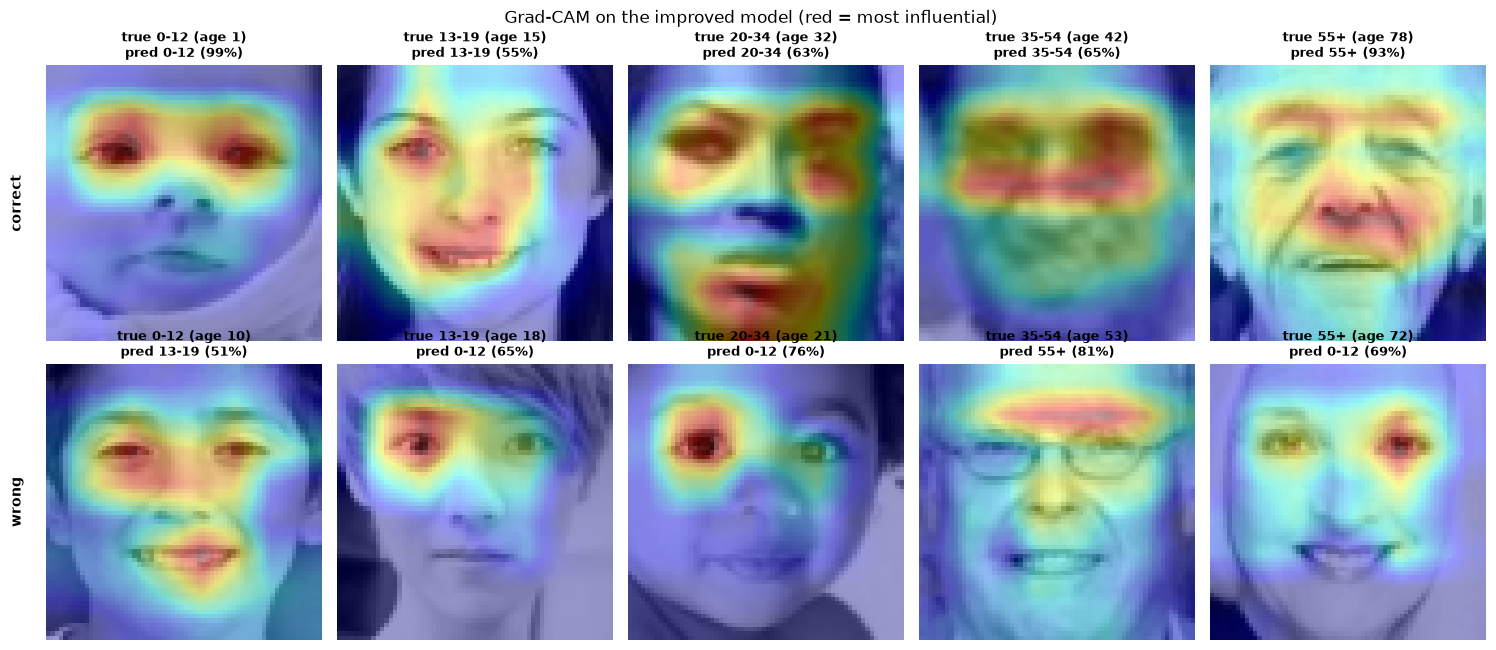

In [27]:
# ---------------------------------------------------------------
# 9.2 Grad-CAM: which parts of the face drive the prediction
# ---------------------------------------------------------------
# A second model that returns both the last conv activations and the prediction
grad_model = keras.Model(improved.inputs, [improved.get_layer("last_conv_act").output, improved.output])

def grad_cam(img):
    """Grad-CAM heatmap for the predicted class. Each conv channel is weighted by how much the
    predicted class score changes with it (its average gradient), the weighted channels are
    summed, and only positive evidence is kept."""
    x = tf.convert_to_tensor(img[None], tf.float32)
    with tf.GradientTape() as tape:
        conv, preds = grad_model(x, training=False)
        cls = int(tf.argmax(preds[0]))
        score = preds[:, cls]
    grads = tape.gradient(score, conv)
    channel_weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * channel_weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    return cam, cls, float(preds[0, cls])

# For each true band: its most confident correct prediction and its most confident mistake
audit["conf_imp"] = imp_probs.max(axis=1)
picks = []
for b in range(N_CLASSES):
    in_band = audit[audit.band_idx == b]
    for correct in (True, False):
        cand = in_band[(in_band.pred_imp == b) == correct]
        if len(cand):
            picks.append((b, correct, cand.sort_values("conf_imp", ascending=False).iloc[0]))

fig, axes = plt.subplots(2, N_CLASSES, figsize=(3 * N_CLASSES, 6.6), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for b, correct, row in picks:
    img = load_image(f"{IMG_DIR}/{row.filename}", IMG_SIZE, GRAY).numpy().astype(np.float32)
    cam, cls, p = grad_cam(img)
    ax = axes[0 if correct else 1, b]
    ax.imshow(img.squeeze() / 255.0, cmap="gray" if GRAY else None)
    ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f"true {BAND_NAMES[b]} (age {row.age})\npred {BAND_NAMES[cls]} ({p:.0%})", fontsize=9)
axes[0, 0].text(-0.08, 0.5, "correct", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center", weight="bold")
axes[1, 0].text(-0.08, 0.5, "wrong", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center", weight="bold")
plt.suptitle("Grad-CAM on the improved model (red = most influential)")
plt.tight_layout(); save_fig("15_grad_cam"); plt.show()

**Findings:** written from the real outputs after the full run.

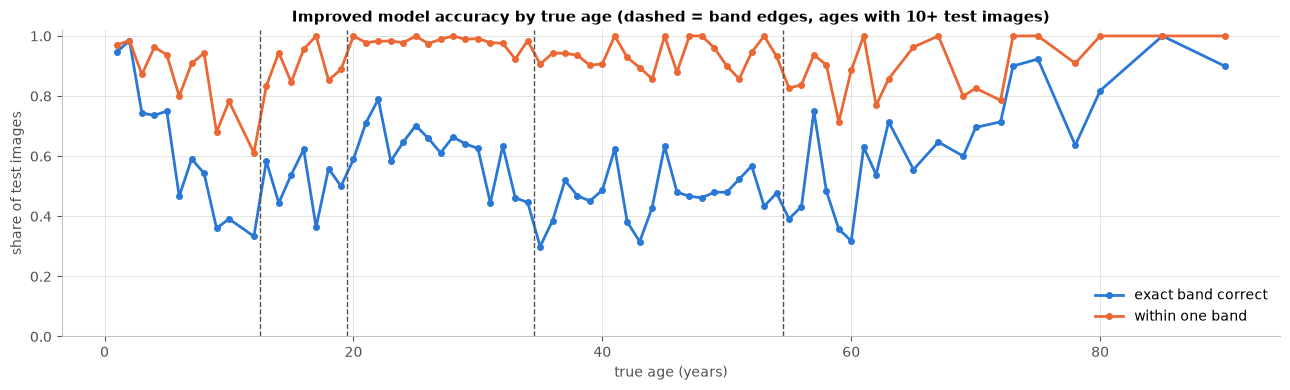

wrong      4.5
correct    6.5

most confident mistakes:
                             filename  age true_band pred_band  conf_imp  gender  race  is_gray
53_0_0_20170111200949284.jpg.chip.jpg   53     35-54       55+  0.814049       0     0    False
48_0_0_20170117164541702.jpg.chip.jpg   48     35-54       55+  0.773442       0     0    False
21_0_4_20161223214834033.jpg.chip.jpg   21     20-34      0-12  0.763692       0     4    False
36_0_0_20170117135444550.jpg.chip.jpg   36     35-54       55+  0.754679       0     0    False
39_0_0_20170103183230555.jpg.chip.jpg   39     35-54       55+  0.742442       0     0    False
42_0_4_20170104174008963.jpg.chip.jpg   42     35-54       55+  0.739418       0     4    False
54_1_0_20170117191408330.jpg.chip.jpg   54     35-54       55+  0.727261       1     0    False
43_0_0_20170112220315153.jpg.chip.jpg   43     35-54       55+  0.723230       0     0    False
54_0_0_20170120223356317.jpg.chip.jpg   54     35-54       55+  0.715689       0

In [28]:
# ---------------------------------------------------------------
# 9.3 Where the errors are: accuracy by true age
# ---------------------------------------------------------------
by_age = (audit.assign(correct=lambda d: d.pred_imp == d.band_idx, near=lambda d: (d.pred_imp - d.band_idx).abs() <= 1)
          .groupby("age").agg(n=("correct", "size"), exact=("correct", "mean"), within_one=("near", "mean")))
# ages with very few test images give noisy rates, so they're left out of the plot
by_age = by_age[by_age.n >= 10]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(by_age.index, by_age.exact, color=CAT_COLOURS[0], lw=2, marker="o", ms=4, label="exact band correct")
ax.plot(by_age.index, by_age.within_one, color=CAT_COLOURS[1], lw=2, marker="o", ms=4, label="within one band")
for edge in BAND_EDGES[1:-1]:
    ax.axvline(edge - 0.5, color=INK2, ls="--", lw=1)
ax.set(xlabel="true age (years)", ylabel="share of test images", ylim=(0, 1.02),
       title="Improved model accuracy by true age (dashed = band edges, ages with 10+ test images)")
ax.legend(loc="lower right")
plt.tight_layout(); save_fig("16_accuracy_by_age"); plt.show()

# How far from the nearest band edge are the mistakes, compared with the correct predictions?
inner_edges = np.array(BAND_EDGES[1:-1])
audit["years_from_edge"] = audit["age"].apply(lambda a: np.min(np.abs(a - (inner_edges - 0.5))))
print(audit.groupby(audit.pred_imp == audit.band_idx)["years_from_edge"].median()
      .rename({True: "correct", False: "wrong"}).rename("median years from nearest band edge").to_string())
print("\nmost confident mistakes:")
worst = audit[audit.pred_imp != audit.band_idx].sort_values("conf_imp", ascending=False).head(10).copy()
worst["true_band"] = [BAND_NAMES[b] for b in worst.band_idx]
worst["pred_band"] = [BAND_NAMES[b] for b in worst.pred_imp]
print(worst[["filename", "age", "true_band", "pred_band", "conf_imp", "gender", "race", "is_gray"]].to_string(index=False))

**Findings:** written from the real outputs after the full run.

In [29]:
# ---------------------------------------------------------------
# 9.4 Save everything the report needs
# ---------------------------------------------------------------
summary = {"input_shape": list(INPUT_SHAPE), "chosen_variant": chosen["variant"],
           "class_weights": {BAND_NAMES[k]: float(v) for k, v in class_weights.items()},
           "baseline_test": {k: float(v) for k, v in m_base_test.items() if k != "model"},
           "improved_test": {k: float(v) for k, v in m_imp_test.items() if k != "model"},
           "baseline_best_epoch": base_hist["best_epoch"], "improved_best_epoch": imp_hist["best_epoch"]}
with open("outputs/summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("saved: models/, figures/, outputs/")

{
  "input_shape": [
    64,
    64,
    1
  ],
  "chosen_variant": "gray_64",
  "class_weights": {
    "0-12": 1.3740425531914893,
    "13-19": 4.041301627033792,
    "20-34": 0.49350450863518264,
    "35-54": 0.8078558919189393,
    "55+": 1.3147394136807817
  },
  "baseline_test": {
    "accuracy": 0.6871023713128976,
    "macro_f1": 0.6429403953288377,
    "weighted_f1": 0.6875335537132948,
    "within_one_band": 0.9719491035280509,
    "quadratic_kappa": 0.8464399169731036
  },
  "improved_test": {
    "accuracy": 0.6043956043956044,
    "macro_f1": 0.5868400332250409,
    "weighted_f1": 0.6219774448191562,
    "within_one_band": 0.94679005205321,
    "quadratic_kappa": 0.778570440584288
  },
  "baseline_best_epoch": 9,
  "improved_best_epoch": 8
}
saved: models/, figures/, outputs/


### 9.5 Final thoughts

Written from the real outputs after the full run.

## References

Abadi, M., Barham, P., Chen, J. et al. 2016. TensorFlow: A system for large-scale machine learning. In: Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI '16). Savannah: USENIX Association, 265-283.

A'Hearn, B., Baten, J. and Crayen, D. 2009. Quantifying quantitative literacy: Age heaping and the history of human capital. The Journal of Economic History, 69(3): 783-808.

Buolamwini, J. and Gebru, T. 2018. Gender shades: Intersectional accuracy disparities in commercial gender classification. In: Proceedings of the 1st Conference on Fairness, Accountability and Transparency. PMLR, 81: 77-91.

Chollet, F. et al. 2015. Keras. [Online]. Available at: https://keras.io [Accessed 19 November 2026].

Cohen, J. 1968. Weighted kappa: Nominal scale agreement with provision for scaled disagreement or partial credit. Psychological Bulletin, 70(4): 213-220.

Ioffe, S. and Szegedy, C. 2015. Batch normalization: Accelerating deep network training by reducing internal covariate shift. In: Proceedings of the 32nd International Conference on Machine Learning. Lille: PMLR, 37: 448-456.

Kingma, D.P. and Ba, J. 2015. Adam: A method for stochastic optimization. In: 3rd International Conference on Learning Representations (ICLR 2015). San Diego.

Krawetz, N. 2013. Kind of like that. The Hacker Factor Blog. [Online]. Available at: https://www.hackerfactor.com/blog/index.php?/archives/529-Kind-of-Like-That.html [Accessed 19 November 2026].

Kruskal, W.H. and Wallis, W.A. 1952. Use of ranks in one-criterion variance analysis. Journal of the American Statistical Association, 47(260): 583-621.

Pech-Pacheco, J.L., Cristóbal, G., Chamorro-Martínez, J. and Fernández-Valdivia, J. 2000. Diatom autofocusing in brightfield microscopy: A comparative study. In: Proceedings of the 15th International Conference on Pattern Recognition. Barcelona: IEEE, 3: 314-317.

Pedregosa, F., Varoquaux, G., Gramfort, A. et al. 2011. Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12: 2825-2830.

Republic of South Africa. 2013. Protection of Personal Information Act 4 of 2013. Government Gazette, 581(37067). Pretoria: Government Printer.

Selvaraju, R.R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. 2017. Grad-CAM: Visual explanations from deep networks via gradient-based localization. In: Proceedings of the IEEE International Conference on Computer Vision (ICCV). Venice: IEEE, 618-626.

Shorten, C. and Khoshgoftaar, T.M. 2019. A survey on image data augmentation for deep learning. Journal of Big Data, 6: 60.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. 2014. Dropout: A simple way to prevent neural networks from overfitting. Journal of Machine Learning Research, 15(56): 1929-1958.

Szegedy, C., Vanhoucke, V., Ioffe, S., Shlens, J. and Wojna, Z. 2016. Rethinking the Inception architecture for computer vision. In: Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR). Las Vegas: IEEE, 2818-2826.

Zaharia, M., Xin, R.S., Wendell, P. et al. 2016. Apache Spark: A unified engine for big data processing. Communications of the ACM, 59(11): 56-65.

Zhang, Z., Song, Y. and Qi, H. 2017. Age progression/regression by conditional adversarial autoencoder. In: Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR). Honolulu: IEEE, 5810-5818. Dataset available at: https://susanqq.github.io/UTKFace/ [Accessed 19 November 2026].